# 3. ECG Signal Preprocessing

## Objective

Prepare the electrocardiographic signals for their later use in deep-learning models.

## Contents

1. [Loading the `.mat` Files](#31-loading-the-mat-files)
2. [Unifying Signal Lengths](#32-unifying-signal-lengths)
3. [Applying Resampling to the Full Dataset](#33-applying-resampling-to-the-full-dataset)
4. [Signal Quality, Outlier Analysis, and Normalization](#34-signal-quality-outlier-analysis-and-normalization)
5. [Final Preprocessing Summary](#35-final-preprocessing-summary)

The notebook follows the workflow below:

1. Load the `.mat` files and the prepared dataset index.
2. Inspect the original signal lengths.
3. Remove baseline drift and resample each signal to 252 samples.
4. Inspect amplitude statistics and investigate extreme signals.
5. Apply per-signal z-score normalization and validate the result.
6. Save the processed signals and their metadata for later modeling.

The train-validation-test split is performed later, while preserving patient identity to prevent information leakage between subsets.

## 3.1 Loading the `.mat` Files

The required libraries are loaded and the dataset index created in Notebook 2 is opened. This section establishes the input data and verifies that the metadata needed for preprocessing is available.

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.io import loadmat
from scipy.signal import resample, detrend, resample_poly
from math import gcd


dataset_index = pd.read_csv("data/dataset_index.csv")

dataset_index = dataset_index.reset_index(
    drop=True
)

required_columns = {
    "mat_path",
    "signal_key",
    "signal_length",
    "original_filename",
    "patient_id",
    "lead",
    "label",
}

y_original = np.asarray(
    dataset_index["label"],
    dtype=int,
)


missing_columns = required_columns - set(dataset_index.columns)

if missing_columns:
    raise KeyError(
        f"Faltan columnas en dataset_index: "
        f"{sorted(missing_columns)}"
    )
display(dataset_index.head())


,patient_id,lead,label,mat_path,original_filename,clean_filename,signal_key,signal_length,signal_dtype,signal_ndim,contains_nan,contains_inf,beat_id
0,BH0002,V1,99,/Users/ainhoa.ns/Desktop/TurraFM/notebooks/dat...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_1_V1_99,ecg_signal,801,float64,1,False,False,BH0002_1_101372_1
1,BH0002,V2,99,/Users/ainhoa.ns/Desktop/TurraFM/notebooks/dat...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_1_V2_99,ecg_signal,801,float64,1,False,False,BH0002_1_101372_1
2,BH0002,V3,99,/Users/ainhoa.ns/Desktop/TurraFM/notebooks/dat...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_1_V3_99,ecg_signal,801,float64,1,False,False,BH0002_1_101372_1
3,BH0002,V4,99,/Users/ainhoa.ns/Desktop/TurraFM/notebooks/dat...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_1_V4_99,ecg_signal,801,float64,1,False,False,BH0002_1_101372_1
4,BH0002,V5,1,/Users/ainhoa.ns/Desktop/TurraFM/notebooks/dat...,Para_alumna_Brugada\all_signals\BH0002_1_10137...,BH0002_1_101372_V5_1,ecg_guardar,252,float64,1,False,False,BH0002_1_101372


## 3.2 Unifying Signal Lengths

The dataset audit identified two signal lengths:
- 252 samples: 6,977 signals.
- 801 samples: 3,615 signals.

One-dimensional convolutional networks require a homogeneous temporal dimension so that signals can be stacked into tensors and processed in batches.

A target length of 252 samples is selected because it is the majority format and allows 6,977 signals to retain their original sampling grid. Signals with 801 samples are resampled to 252 points by interpolation.

Before applying the transformation to the full dataset, several signals are inspected visually to assess whether resampling preserves their morphology.

### 3.2.1 Defining the Target Length

In [7]:
# Target length for all signals.
target_length = 252

# Create the column that records each signal's length after resampling.
dataset_index["new_length"] = target_length

print(
    "Original length distribution:"
)

display(
    dataset_index["signal_length"]
    .value_counts()
    .sort_index()
)


Original length distribution:


signal_length
252    6977
801    3615
Name: count, dtype: int64

### 3.2.2 Functions for Loading and Resampling Signals

A helper function is defined to load one signal. Baseline drift is removed from every signal, and a second function is defined to resample only signals with 801 samples.

Interpolation is performed on a normalized time axis from 0 to 1. This compares relative positions within the beat rather than absolute sample indices.

In [8]:
def load_ecg_signal(row):
    """
    Load a signal using only the information in the mat_path column.
    """
    mat_data = loadmat(
        row["mat_path"],
        squeeze_me=True, # elimina dimensiones innecesarias ( (252,1) -> (252, ))
    )

    ecg_signal = np.asarray(
        mat_data[row["signal_key"]]
    )

    return ecg_signal

def remove_baseline_drift(ecg_signal):
    return detrend(
        np.asarray(ecg_signal, dtype=float),
        type="linear",
    )



baseline_signals = []

for _, row in dataset_index.iterrows():
    ecg_signal = load_ecg_signal(row)

    # Remove baseline drift.
    baseline_corrected_signal = remove_baseline_drift(
        ecg_signal
    )
    baseline_signals.append(
        baseline_corrected_signal
    )





In [9]:
def resample_signal_252(baseline_corrected_signal):
    """
    Resample a signal to 252 samples using
    remuestreo polifásico.
    """
    baseline_corrected_signal = np.asarray(
        baseline_corrected_signal,
        dtype=float,
    )

    original_length = len(baseline_corrected_signal)

    if original_length == target_length:
        return baseline_corrected_signal.copy()

    if original_length != 801:
        raise ValueError(
            f"Unexpected length: {original_length}"
        )

    common_divisor = gcd(
        original_length,
        target_length,
    )

    up = target_length // common_divisor
    down = original_length // common_divisor

    resampled_signal = resample_poly(
        baseline_corrected_signal,
        up=up,
        down=down,
    )

    # Guarantee exactly 252 samples.
    return resampled_signal[:target_length]





### 3.2.3 Individual Signal Checks

Before processing the full dataset, one signal with 252 samples is selected and passed through the same procedure. The result is checked to confirm that its length and values are unchanged. A signal with 801 samples is then inspected to verify the expected reduction to 252 samples.

In [10]:
# Select a signal that already has 252 samples.
example_252 = (
    dataset_index[
        dataset_index["signal_length"] == target_length
    ]
    .iloc[0]
)

# Load the original signal.
original_signal_252 = load_ecg_signal(
    example_252
)

baseline_corrected_signal_252 = remove_baseline_drift(
    original_signal_252
)

# Apply polyphase resampling.
processed_signal_252 = resample_signal_252(
    baseline_corrected_signal_252
)

signal_252_is_equal = (
    np.allclose(
        processed_signal_252,
        baseline_corrected_signal_252,
    )
)

print(
    f"File: "
    f"{example_252['original_filename']}"
)

print(
    f"Original length: "
    f"{len(original_signal_252)}"
)

print(
    f"Length after processing: "
    f"{len(processed_signal_252)}"
)

print(
    f"Values remain exactly unchanged: "
    f"{signal_252_is_equal}"
)

File: Para_alumna_Brugada\all_signals\BH0002_1_101372_V5_1.mat
Original length: 252
Length after processing: 252
Values remain exactly unchanged: True


In [11]:
# Select a signal with 801 samples.
example_801_row = (
    dataset_index[
        dataset_index["signal_length"] == 801
    ]
    .iloc[0]
)

# Load the original signal.
original_signal_801 = load_ecg_signal(
    example_801_row
)

baseline_corrected_signal_801 = remove_baseline_drift(
    original_signal_801
)

# Apply polyphase resampling.
processed_signal_801 = resample_signal_252(
    baseline_corrected_signal_801
)


# Create normalized time axes.
time_801 = np.linspace(
    0,
    1,
    len(original_signal_801),
)

time_252 = np.linspace(
    0,
    1,
    len(processed_signal_801),
)

print(
    f"File: "
    f"{example_801_row['original_filename']}"
)

print(
    f"Original length: "
    f"{len(original_signal_801)}"
)

print(
    f"Length after resampling: "
    f"{len(processed_signal_801)}"
)

plt.figure(figsize=(12, 5))

plt.plot(
    time_801,
    original_signal_801,
    label="Original: 801 samples",
    linewidth=2,
    alpha=0.7,
)

plt.plot(
    time_801,
    baseline_corrected_signal_801,
    label="Baseline-corrected: 801 samples",
    linewidth=1.2,
)

plt.plot(
    time_252,
    processed_signal_801,
    label="Resampled: 252 samples",
    linewidth=1.2,
)

plt.title(
    f"Resampling a signal from 801 to 252 samples\n"
    f"Patient: {example_801_row['patient_id']} | "
    f"Lead: {example_801_row['lead']} | "
    f"Class: {example_801_row['label']}"
)

plt.xlabel("Relative position within the beat")
plt.ylabel("Amplitude")
plt.xlim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

File: Para_alumna_Brugada\all_signals\BH0002_1_101372_1_V1_99.mat
Original length: 801
Length after resampling: 252


<Figure size 1200x500 with 1 Axes>

## 3.3 Applying Resampling to the Full Dataset

Each file is processed according to the following rules:

- Baseline drift is removed from every signal.
- Signals with 252 samples are copied without resampling.
- Signals with 801 samples are resampled to 252 samples.
- No new `.mat` files are created.
- Processed signals are temporarily kept in memory as a NumPy array.
- The `new_length` column records the final length of each signal.

In [ ]:
processed_signals = []
new_lengths = []

total_files = len(dataset_index)

for file_number, (_, row) in enumerate(
    dataset_index.iterrows(),
    start=1,
):
    # Load the original signal.
    ecg_signal = load_ecg_signal(row)

    # Remove linear baseline drift.
    baseline_corrected_signal = detrend(
        np.asarray(
            ecg_signal,
            dtype=float,
        ),
        type="linear",
    )

    # Resample to 252 samples.
    processed_signal = resample_signal_252(
        baseline_corrected_signal
    )

    # Store the processed signal.
    processed_signals.append(
        processed_signal
    )

    # Record the final length.
    new_lengths.append(
        len(processed_signal)
    )

    if file_number % 1000 == 0:
        print(
            f"Processed {file_number} "
            f"of {total_files} signals"
        )

# Convert all signals into a matrix.
processed_signals_array = np.stack(
    processed_signals
)

# Update the final length.
dataset_index["new_length"] = new_lengths

print(
    f"Final array shape: "
    f"{processed_signals_array.shape}"
)

print(
    f"Data type: "
    f"{processed_signals_array.dtype}"
)

Procesadas 1000 of 10592 signals
Procesadas 2000 of 10592 signals
Procesadas 3000 of 10592 signals
Procesadas 4000 of 10592 signals
Procesadas 5000 of 10592 signals
Procesadas 6000 of 10592 signals
Procesadas 7000 of 10592 signals
Procesadas 8000 of 10592 signals
Procesadas 9000 of 10592 signals
Procesadas 10000 of 10592 signals
Final array shape: (10592, 252)
Data type: float64


In [13]:
# Check that all signals have 252 samples.
all_signals_have_252_samples = (
    processed_signals_array.shape[1]
    == target_length
)

all_new_lengths_are_252 = (
    dataset_index["new_length"] == target_length
).all()

# Check that there are no NaN values.
contains_nan_after_resampling = np.isnan(
    processed_signals_array
).any()

# Check that there are no infinite values.
contains_inf_after_resampling = np.isinf(
    processed_signals_array
).any()

# Count how many original signals had each length.
number_of_original_252 = (
    dataset_index["signal_length"] == target_length
).sum()

number_of_original_801 = (
    dataset_index["signal_length"] == 801
).sum()



print(
    "All signals have 252 samples:",
    all_signals_have_252_samples,
)

print(
    "All rows have new_length equal to 252:",
    all_new_lengths_are_252,
)

print(
    "Number of original 252-sample signals:",
    number_of_original_252,
)

print(
    "Number of original 801-sample signals:",
    number_of_original_801,
)

print(
    "Existen valores NaN después del remuestreo:",
    contains_nan_after_resampling,
)

print(
    "Existen valores Inf después del remuestreo:",
    contains_inf_after_resampling,
)


All signals have 252 samples: True
All rows have new_length equal to 252: True
Number of original 252-sample signals: 6977
Number of original 801-sample signals: 3615
Existen valores NaN después del remuestreo: False
Existen valores Inf después del remuestreo: False


In [67]:
# Additional verification for signals that originally had 252 samples.
# These signals should be identical to their baseline-corrected versions
# because resampling is a no-op when the length is already 252.

original_252_indices = dataset_index.index[
    dataset_index["signal_length"] == target_length
]

unchanged_after_resampling = True
maximum_difference = 0.0

for index in original_252_indices:
    baseline_corrected_signal = baseline_signals[index]
    processed_signal = processed_signals_array[index]

    difference = np.max(
        np.abs(
            processed_signal
            - baseline_corrected_signal
        )
    )

    maximum_difference = max(
        maximum_difference,
        difference,
    )

    if not np.allclose(
        processed_signal,
        baseline_corrected_signal,
        rtol=1e-5,
        atol=1e-8,
    ):
        unchanged_after_resampling = False
        break

print(
    "Original 252-sample signals were not altered by resampling:",
    unchanged_after_resampling,
)

print(
    "Maximum difference after detrending:",
    maximum_difference,
)

Original 252-sample signals were not altered by resampling: True
Maximum difference after detrending: 0.0


### Saved Resampled Signals

In [15]:
# Save the resampled signals together with the metadata for each row.
np.savez_compressed(
    "data/processed_signals_252.npz",
    signals=processed_signals_array,
    patient_id=dataset_index["patient_id"].to_numpy(dtype=str),
    lead=dataset_index["lead"].to_numpy(dtype=str),
    label=dataset_index["label"].to_numpy(dtype=int),
    mat_path=dataset_index["mat_path"].astype(str).to_numpy(dtype=str),
)

print("File saved successfully.")


File saved successfully.


In [ ]:
processed_data = np.load(
    "data/processed_signals_252.npz"
)

signals_252 = processed_data["signals"]
patient_ids = processed_data["patient_id"]
leads = processed_data["lead"]
labels = processed_data["label"]
mat_paths = processed_data["mat_path"]

Shape: (10592, 252)
Signal data type: float64


## 3.4 Signal Quality, Outlier Analysis, and Normalization

### 3.4.1 Pre-normalization Analysis

In [18]:
# Signal statistics

signals_stats = pd.DataFrame({
    "signal_index": np.arange(len(signals_252)),
    "mean": np.mean(signals_252, axis=1),
    "std": np.std(signals_252, axis=1),
    "min": np.min(signals_252, axis=1),
    "max": np.max(signals_252, axis=1),
    "range": np.ptp(signals_252, axis=1),
})

signals_stats.describe()

,signal_index,mean,std,min,max,range
count,10592.00000,1.059200e+04,10592.000000,10592.000000,10592.000000,10592.000000
mean,5295.50000,-5.307199e-03,61.365704,-271.700034,149.439724,421.139757
std,3057.79136,3.778305e-02,27.403195,127.031396,102.636899,184.125668
min,0.00000,-5.596548e-01,8.753073,-859.177306,19.322702,38.765749
25%,2647.75000,-7.579123e-14,40.161282,-345.619294,81.813170,287.637750
50%,5295.50000,-3.383537e-16,56.083483,-240.282601,118.016418,374.224818
75%,7943.25000,6.934488e-15,77.064822,-184.108584,182.068014,524.851198
max,10591.00000,7.702272e-01,320.522397,-16.989158,809.307150,1580.234800


### 3.4.2 Exploring Signal Statistics

The signals show substantial amplitude differences. This subsection investigates their distribution and determines whether the largest values are isolated artifacts or systematic patterns associated with particular patients or leads.

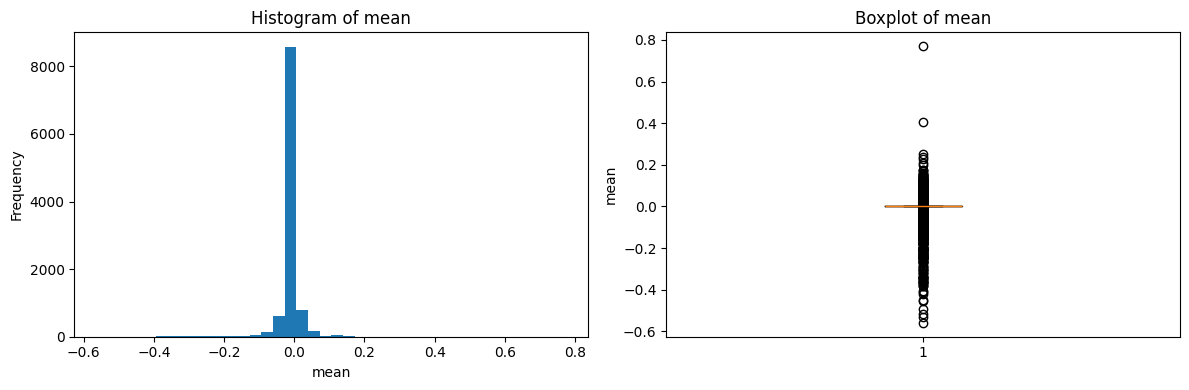

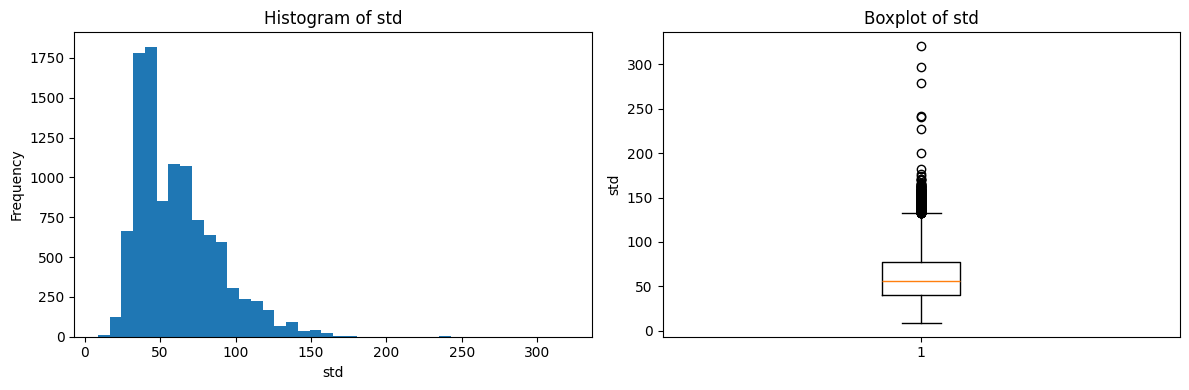

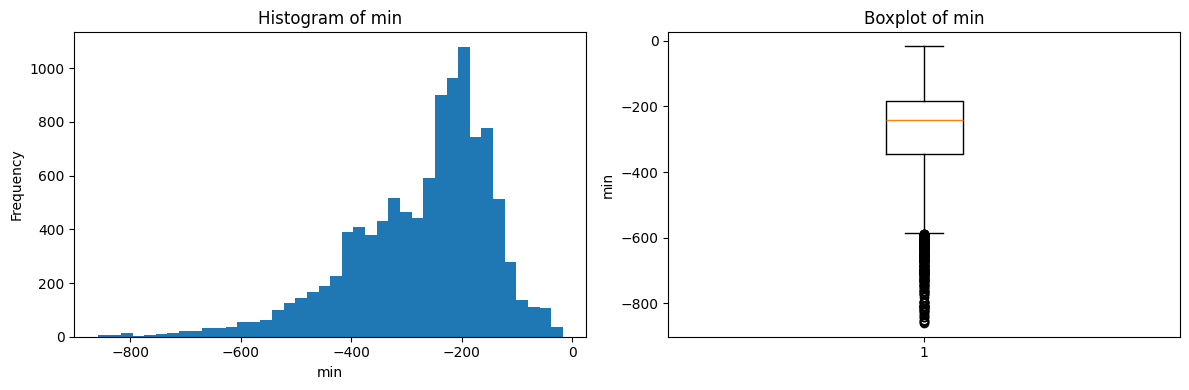

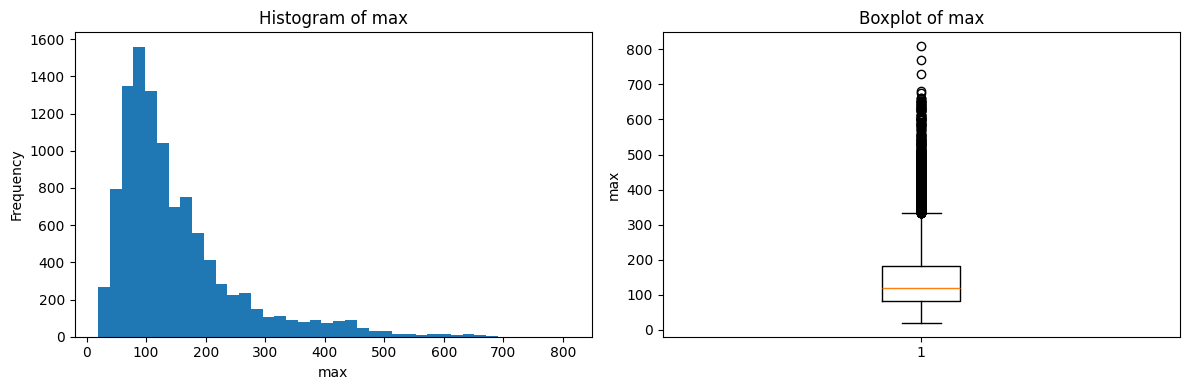

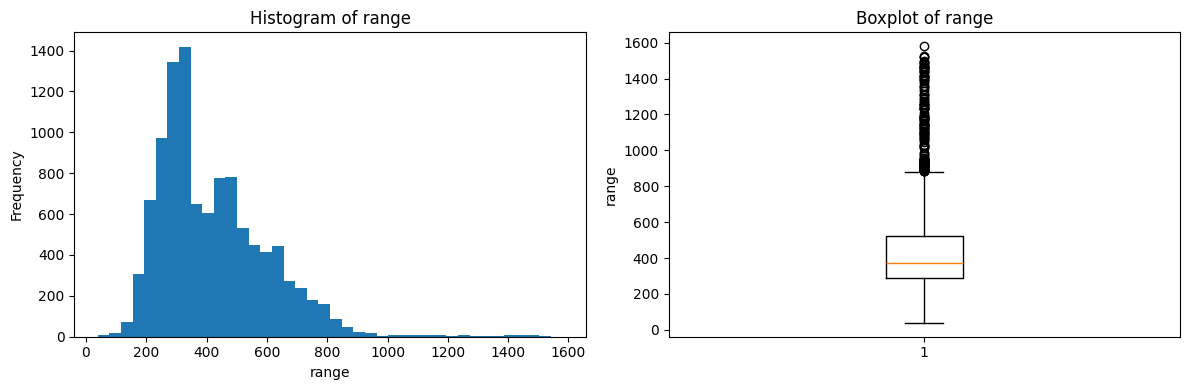

In [19]:
stats_columns = [
    "mean",
    "std",
    "min",
    "max",
    "range",
]

for column in stats_columns:
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(12, 4),
    )

    # Histogram
    axes[0].hist(
        signals_stats[column],
        bins=40,
    )
    axes[0].set_title(
        f"Histogram of {column}"
    )
    axes[0].set_xlabel(column)
    axes[0].set_ylabel("Frequency")

    # Boxplot vertical
    axes[1].boxplot(
        signals_stats[column],
        vert=True,
    )
    axes[1].set_title(
        f"Boxplot of {column}"
    )
    axes[1].set_ylabel(column)

    plt.tight_layout()
    plt.show()

#### 3.4.2.1 Extreme-Signal Analysis

The ten signals with the following extreme statistics are identified:

- Largest standard deviation.
- Most negative minimum value.
- Most positive maximum value.
- Largest amplitude range.

The analysis also checks whether the same signal appears in more than one category.

In [20]:
# Indices of the 10 most extreme signals for each statistic.

# Indices of the 10 signals with the largest standard deviation.
top_std_indices = (
    signals_stats
    .nlargest(10, "std")
    .index
    .to_numpy()
)

# Indices of the 10 signals with the most negative minimum.
most_negative_min_indices = (
    signals_stats
    .nsmallest(10, "min")
    .index
    .to_numpy()
)

# Indices of the 10 signals with the most positive maximum.
most_positive_max_indices = (
    signals_stats
    .nlargest(10, "max")
    .index
    .to_numpy()
)

# Indices of the 10 signals with the largest range.
top_range_indices = (
    signals_stats
    .nlargest(10, "range")
    .index
    .to_numpy()
)

# Detailed table for each category.

top_std = (
    signals_stats
    .nlargest(10, "std")
    .sort_values("std", ascending=False)
)

# 10 signals with the most negative minimum.
most_negative_min = (
    signals_stats
    .nsmallest(10, "min")
    .sort_values("min", ascending=True)
)

# 10 signals with the most positive maximum.
most_positive_max = (
    signals_stats
    .nlargest(10, "max")
    .sort_values("max", ascending=False)
)

# 10 signals with the largest amplitude range.
top_range = (
    signals_stats
    .nlargest(10, "range")
    .sort_values("range", ascending=False)
)

print("10 signals with the largest standard deviation")
display(top_std)

print("10 signals with the most negative minimum")
display(most_negative_min)

print("10 signals with the most positive maximum")
display(most_positive_max)

print("10 signals with the largest range")
display(top_range)

10 signals with the largest standard deviation


,signal_index,mean,std,min,max,range
10091,10091,0.770227,320.522397,-724.388460,770.814284,1495.202744
9550,9550,-0.045636,296.603840,-610.139041,625.051102,1235.190143
9568,9568,0.009403,279.024874,-704.195435,462.244623,1166.440058
9562,9562,0.120018,242.006968,-724.212228,511.209501,1235.421729
9580,9580,0.042064,240.706890,-291.833458,809.307150,1101.140608
9544,9544,-0.494643,227.008721,-446.854362,528.855672,975.710035
9613,9613,-0.178174,200.650819,-409.817618,537.832917,947.650535
9592,9592,0.227097,181.773224,-285.287713,468.991322,754.279035
10488,10488,-0.368515,175.978761,-285.739971,445.877779,731.617750
10491,10491,-0.383342,174.320378,-281.639320,447.292853,728.932173


10 signals with the most negative minimum


,signal_index,mean,std,min,max,range
5459,5459,4.849736e-15,161.925907,-859.177306,660.543701,1519.721007
5483,5483,3.721891e-15,161.861400,-855.916975,662.256538,1518.173513
5477,5477,-4.511382e-15,162.286741,-853.199274,674.357279,1527.556553
5453,5453,-4.398598e-15,164.701354,-851.541819,728.692981,1580.234800
5441,5441,-2.594045e-15,158.493813,-840.633860,650.384982,1491.018842
5435,5435,-1.094010e-14,161.052548,-840.409059,653.031546,1493.440605
5417,5417,-1.804553e-15,158.203230,-835.845392,632.363359,1468.208751
5381,5381,3.721891e-15,158.216332,-832.652237,648.298730,1480.950967
5231,5231,1.804553e-15,152.129620,-824.971665,588.996778,1413.968442
5447,5447,1.172959e-14,156.423412,-824.151857,614.502140,1438.653998


10 signals with the most positive maximum


,signal_index,mean,std,min,max,range
9580,9580,4.206407e-02,240.706890,-291.833458,809.307150,1101.140608
10091,10091,7.702272e-01,320.522397,-724.388460,770.814284,1495.202744
5453,5453,-4.398598e-15,164.701354,-851.541819,728.692981,1580.234800
5387,5387,9.473903e-15,157.953148,-807.622945,680.925823,1488.548768
5477,5477,-4.511382e-15,162.286741,-853.199274,674.357279,1527.556553
5483,5483,3.721891e-15,161.861400,-855.916975,662.256538,1518.173513
5459,5459,4.849736e-15,161.925907,-859.177306,660.543701,1519.721007
5423,5423,-2.481260e-15,154.652586,-807.702909,657.731317,1465.434226
5435,5435,-1.094010e-14,161.052548,-840.409059,653.031546,1493.440605
5411,5411,3.045183e-15,153.444794,-813.786729,652.155227,1465.941956


10 signals with the largest range


,signal_index,mean,std,min,max,range
5453,5453,-4.398598e-15,164.701354,-851.541819,728.692981,1580.234800
5477,5477,-4.511382e-15,162.286741,-853.199274,674.357279,1527.556553
5459,5459,4.849736e-15,161.925907,-859.177306,660.543701,1519.721007
5483,5483,3.721891e-15,161.861400,-855.916975,662.256538,1518.173513
10091,10091,7.702272e-01,320.522397,-724.388460,770.814284,1495.202744
5435,5435,-1.094010e-14,161.052548,-840.409059,653.031546,1493.440605
5441,5441,-2.594045e-15,158.493813,-840.633860,650.384982,1491.018842
5387,5387,9.473903e-15,157.953148,-807.622945,680.925823,1488.548768
5381,5381,3.721891e-15,158.216332,-832.652237,648.298730,1480.950967
5489,5489,-3.834675e-15,156.331742,-817.464658,651.389796,1468.854454


### Checking Overlap Between Extreme-Signal Categories

In [21]:
extreme_categories = {
    "top_std": set(top_std_indices),
    "most_negative_min": set(most_negative_min_indices),
    "most_positive_max": set(most_positive_max_indices),
    "top_range": set(top_range_indices),
}

all_extreme_indices = sorted(
    set().union(*extreme_categories.values())
)

# Create a table with all extreme-signal indices.
extreme_overlap = pd.DataFrame({
    "signal_index": all_extreme_indices,
})

# Record the categories to which each signal belongs.
for category_name, category_indices in (
    extreme_categories.items()
):
    extreme_overlap[category_name] = (
        extreme_overlap["signal_index"]
        .isin(category_indices)
    )

# Count how many categories contain each signal.
category_columns = list(
    extreme_categories.keys()
)

extreme_overlap["number_of_categories"] = (
    extreme_overlap[category_columns]
    .sum(axis=1)
)



# Add the corresponding statistics for each signal.
extreme_overlap = (
    extreme_overlap
    .merge(
        signals_stats,
        on="signal_index",
        how="left",
    )
    .sort_values(
        "number_of_categories",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(extreme_overlap)



,signal_index,top_std,most_negative_min,most_positive_max,top_range,number_of_categories,mean,std,min,max,range
0,5483,False,True,True,True,3,3.721891e-15,161.861400,-855.916975,662.256538,1518.173513
1,10091,True,False,True,True,3,7.702272e-01,320.522397,-724.388460,770.814284,1495.202744
2,5435,False,True,True,True,3,-1.094010e-14,161.052548,-840.409059,653.031546,1493.440605
3,5453,False,True,True,True,3,-4.398598e-15,164.701354,-851.541819,728.692981,1580.234800
4,5459,False,True,True,True,3,4.849736e-15,161.925907,-859.177306,660.543701,1519.721007
5,5477,False,True,True,True,3,-4.511382e-15,162.286741,-853.199274,674.357279,1527.556553
6,5387,False,False,True,True,2,9.473903e-15,157.953148,-807.622945,680.925823,1488.548768
7,5441,False,True,False,True,2,-2.594045e-15,158.493813,-840.633860,650.384982,1491.018842
8,5381,False,True,False,True,2,3.721891e-15,158.216332,-832.652237,648.298730,1480.950967
9,9580,True,False,True,False,2,4.206407e-02,240.706890,-291.833458,809.307150,1101.140608


In [22]:
# Add the metadata for each signal.
signals_stats["patient_id"] = (
    dataset_index["patient_id"].to_numpy()
)

signals_stats["lead"] = (
    dataset_index["lead"].to_numpy()
)

signals_stats["label"] = (
    dataset_index["label"].to_numpy()
)

print(signals_stats.columns)
display(signals_stats.head())

Index(['signal_index', 'mean', 'std', 'min', 'max', 'range', 'patient_id',
       'lead', 'label'],
      dtype='object')


,signal_index,mean,std,min,max,range,patient_id,lead,label
0,0,-5.620460e-03,41.655354,-236.368822,62.242692,298.611514,BH0002,V1,99
1,1,-2.842341e-02,35.001990,-195.734400,57.378970,253.113370,BH0002,V2,99
2,2,-6.478057e-03,43.234419,-238.664485,81.173277,319.837762,BH0002,V3,99
3,3,-2.401302e-02,37.492556,-178.630701,94.362152,272.992853,BH0002,V4,99
4,4,-2.729386e-14,42.252041,-220.947176,101.378403,322.325579,BH0002,V5,1


In [23]:
# Summarize the overlap.

print(
    "Number of unique extreme signals:",
    len(all_extreme_indices),
)

print(
    "Signals present in more than one category:",
    (
        extreme_overlap["number_of_categories"] > 1
    ).sum(),
)

print(
    "Signals present in all four categories:",
    (
        extreme_overlap["number_of_categories"] == 4
    ).sum(),
)

Number of unique extreme signals: 24
Signals present in more than one category: 10
Signals present in all four categories: 0


### Concentration of Extreme Signals by Patient and Lead

In [24]:
unique_extreme_signals = (
    signals_stats[
        signals_stats["signal_index"]
        .isin(all_extreme_indices)
    ]
    .copy()
)

# Analyze whether extreme signals are concentrated
# in particular patients.
patient_concentration = (
    unique_extreme_signals
    .groupby("patient_id")
    .agg(
        extreme_signals=(
            "signal_index",
            "nunique",
        ),
        leads=(
            "lead",
            "nunique",
        ),
    )
    .sort_values(
        "extreme_signals",
        ascending=False,
    )
)

# Analyze whether extreme signals are concentrated
# in particular leads.
lead_concentration = (
    unique_extreme_signals
    .groupby("lead")
    .agg(
        extreme_signals=(
            "signal_index",
            "nunique",
        ),
        patients=(
            "patient_id",
            "nunique",
        ),
    )
    .sort_values(
        "extreme_signals",
        ascending=False,
    )
)


print("Concentration by patient")
display(patient_concentration)

print("Concentration by lead")
display(lead_concentration)

Concentration by patient


,extreme_signals,leads
patient_id,,
BH0020,14,1
BH0035,7,2
BH0101,2,1
BH0044,1,1


Concentration by lead


,extreme_signals,patients
lead,,
V6,21,3
V3,2,1
V5,1,1


In [25]:
# Joint distribution by patient and lead.

patient_lead_concentration = (
    unique_extreme_signals
    .groupby(
        ["patient_id", "lead"]
    )
    .size()
    .reset_index(
        name="extreme_signals"
    )
    .sort_values(
        "extreme_signals",
        ascending=False,
    )
)

display(patient_lead_concentration)

,patient_id,lead,extreme_signals
0,BH0020,V6,14
2,BH0035,V6,6
4,BH0101,V3,2
1,BH0035,V5,1
3,BH0044,V6,1


Key findings:
- 40 positions were selected, corresponding to 24 unique signals.
- 10 signals appear in more than one category.
- No signal appears simultaneously in all four categories.

The main concentration is:
- Patient BH0020: 14 extreme signals, all in V6.
- Patient BH0035: 7 extreme signals, mainly in V6.
- Patient BH0101: 2 signals in V3.
- Patient BH0044: 1 signal in V6.

By lead:
- V6: 21 of the 24 unique extreme signals.
- V3: 2 signals.
- V5: 1 signal.

All 40 extreme positions belong to label 99.

The strongest concentration is in patient BH0020, lead V6, and label 99 (8 of the 10 most extreme signals).

### Analysis of the Ten Most Extreme Signals

In [26]:
signals_to_review = [
    5453,
    5477,
    5459,
    5483,
    10091,
    5387,
    5441,
    5381,
    9580,
    9562,
]

signals_to_review_table = (
    signals_stats[
        signals_stats["signal_index"]
        .isin(signals_to_review)
    ]
    .sort_values(
        "range",
        ascending=False,
    )
)

display(
    signals_to_review_table[
        [
            "signal_index",
            "patient_id",
            "lead",
            "label",
            "mean",
            "std",
            "min",
            "max",
            "range",
        ]
    ]
)

,signal_index,patient_id,lead,label,mean,std,min,max,range
5453,5453,BH0020,V6,99,-4.398598e-15,164.701354,-851.541819,728.692981,1580.234800
5477,5477,BH0020,V6,99,-4.511382e-15,162.286741,-853.199274,674.357279,1527.556553
5459,5459,BH0020,V6,99,4.849736e-15,161.925907,-859.177306,660.543701,1519.721007
5483,5483,BH0020,V6,99,3.721891e-15,161.861400,-855.916975,662.256538,1518.173513
10091,10091,BH0044,V6,99,7.702272e-01,320.522397,-724.388460,770.814284,1495.202744
5441,5441,BH0020,V6,99,-2.594045e-15,158.493813,-840.633860,650.384982,1491.018842
5387,5387,BH0020,V6,99,9.473903e-15,157.953148,-807.622945,680.925823,1488.548768
5381,5381,BH0020,V6,99,3.721891e-15,158.216332,-832.652237,648.298730,1480.950967
9562,9562,BH0035,V6,99,1.200181e-01,242.006968,-724.212228,511.209501,1235.421729
9580,9580,BH0035,V6,99,4.206407e-02,240.706890,-291.833458,809.307150,1101.140608


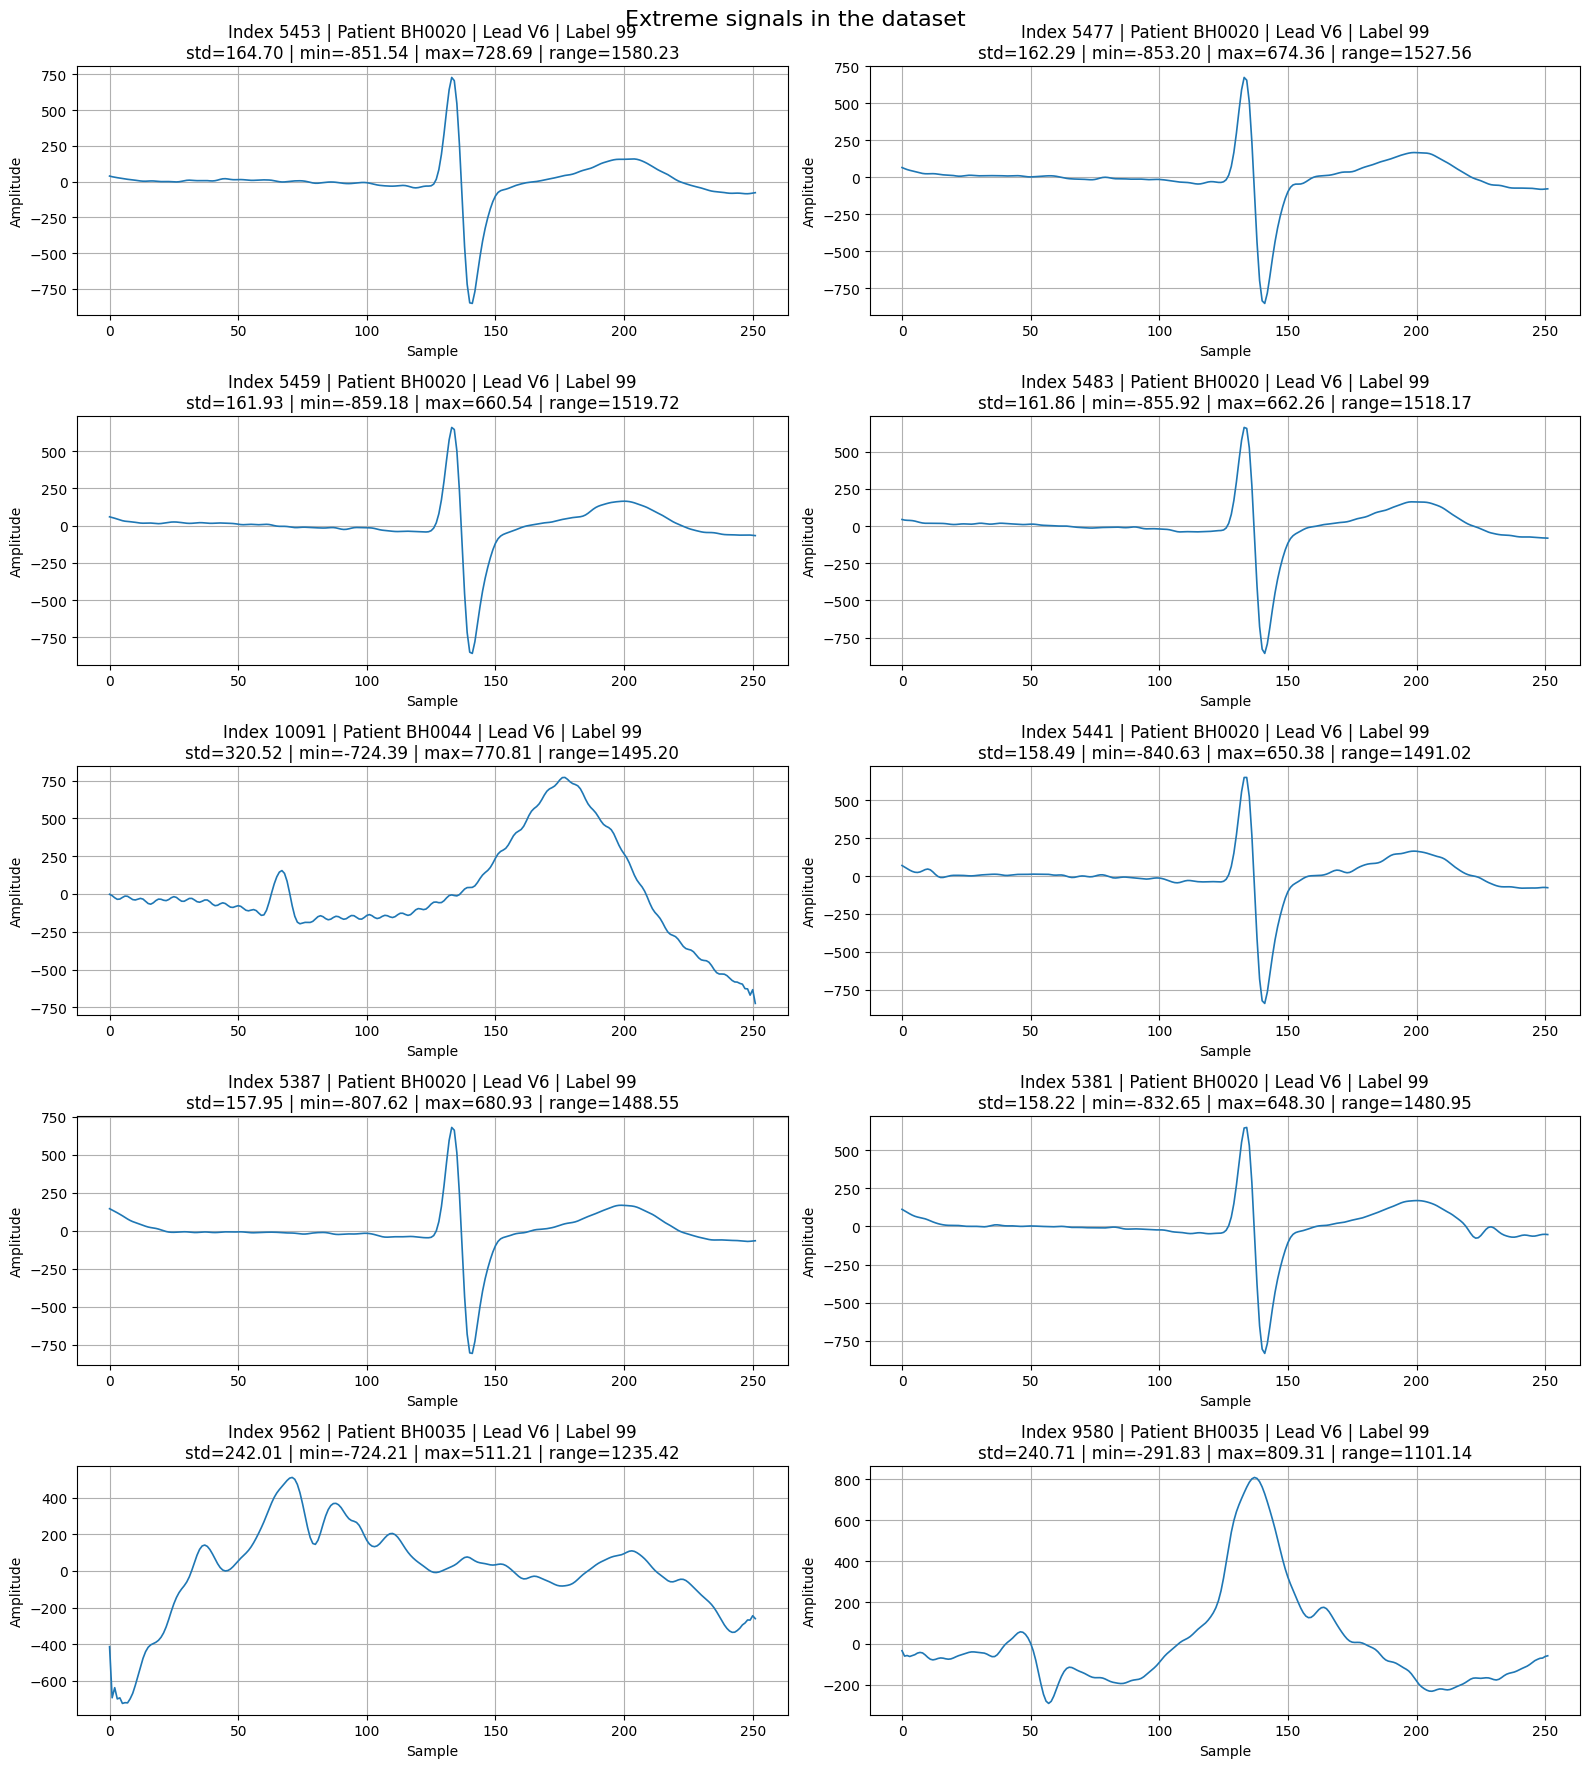

In [27]:
signals_to_plot = [
    5453,
    5477,
    5459,
    5483,
    10091,
    5441,
    5387,
    5381,
    9562,
    9580,
]

fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(16, 18),
)

for axis, signal_index in zip(
    axes.ravel(),
    signals_to_plot,
):
    # Retrieve the processed signal.
    signal = processed_signals_array[
        signal_index
    ]

    # Retrieve the statistics and metadata
    # corresponding to that signal.
    metadata = (
        signals_stats[
            signals_stats["signal_index"]
            == signal_index
        ]
        .iloc[0]
    )

    axis.plot(
        signal,
        linewidth=1.2,
    )

    axis.set_title(
        f"Index {signal_index} | "
        f"Patient {metadata['patient_id']} | "
        f"Lead {metadata['lead']} | "
        f"Label {metadata['label']}\n"
        f"std={metadata['std']:.2f} | "
        f"min={metadata['min']:.2f} | "
        f"max={metadata['max']:.2f} | "
        f"range={metadata['range']:.2f}"
    )

    axis.set_xlabel("Sample")
    axis.set_ylabel("Amplitude")
    axis.grid(True)

fig.suptitle(
    "Extreme signals in the dataset",
    fontsize=16,
)

fig.tight_layout()
plt.show()

#### 3.4.2.2 Analysis of Patient BH0020

The signals from BH0020 do not appear to be visual anomalies. The specific statistics for this patient are analyzed in more detail.

In [28]:
bh0020_v6 = signals_stats[
    (signals_stats["patient_id"] == "BH0020")
    & (signals_stats["lead"] == "V6")
]

display(
    bh0020_v6[
        [
            "signal_index",
            "std",
            "min",
            "max",
            "range",
        ]
    ].sort_values(
        "range",
        ascending=False,
    )
)


,signal_index,std,min,max,range
5453,5453,164.701354,-851.541819,728.692981,1580.234800
5477,5477,162.286741,-853.199274,674.357279,1527.556553
5459,5459,161.925907,-859.177306,660.543701,1519.721007
5483,5483,161.861400,-855.916975,662.256538,1518.173513
5435,5435,161.052548,-840.409059,653.031546,1493.440605
5441,5441,158.493813,-840.633860,650.384982,1491.018842
5387,5387,157.953148,-807.622945,680.925823,1488.548768
5381,5381,158.216332,-832.652237,648.298730,1480.950967
5489,5489,156.331742,-817.464658,651.389796,1468.854454
5417,5417,158.203230,-835.845392,632.363359,1468.208751


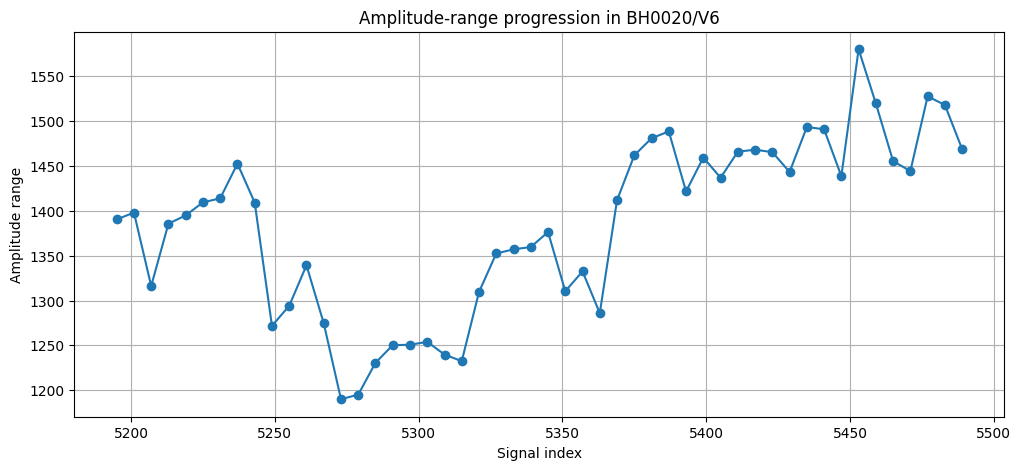

In [29]:
plt.figure(figsize=(12, 5))

plt.plot(
    bh0020_v6.index,
    signals_stats.loc[
        bh0020_v6.index,
        "range",
    ],
    marker="o",
)

plt.title(
    "Amplitude-range progression in BH0020/V6"
)

plt.xlabel("Signal index")
plt.ylabel("Amplitude range")
plt.grid(True)
plt.show()

The elevated amplitude is systematic for this patient and lead.
There is beat-to-beat variation, but no isolated implausible peak.
This plot alone does not show a clearly corrupted signal.

In [30]:
# Number of extreme signals to plot
# for each lead.
top_n_per_lead = 10

# Select signals from patient BH0020
# with the largest range within each lead.
bh0020_extreme_by_lead = (
    signals_stats[
        signals_stats["patient_id"] == "BH0020"
    ]
    .sort_values(
        ["lead", "range"],
        ascending=[True, False],
    )
    .groupby("lead")
    .head(top_n_per_lead)
)

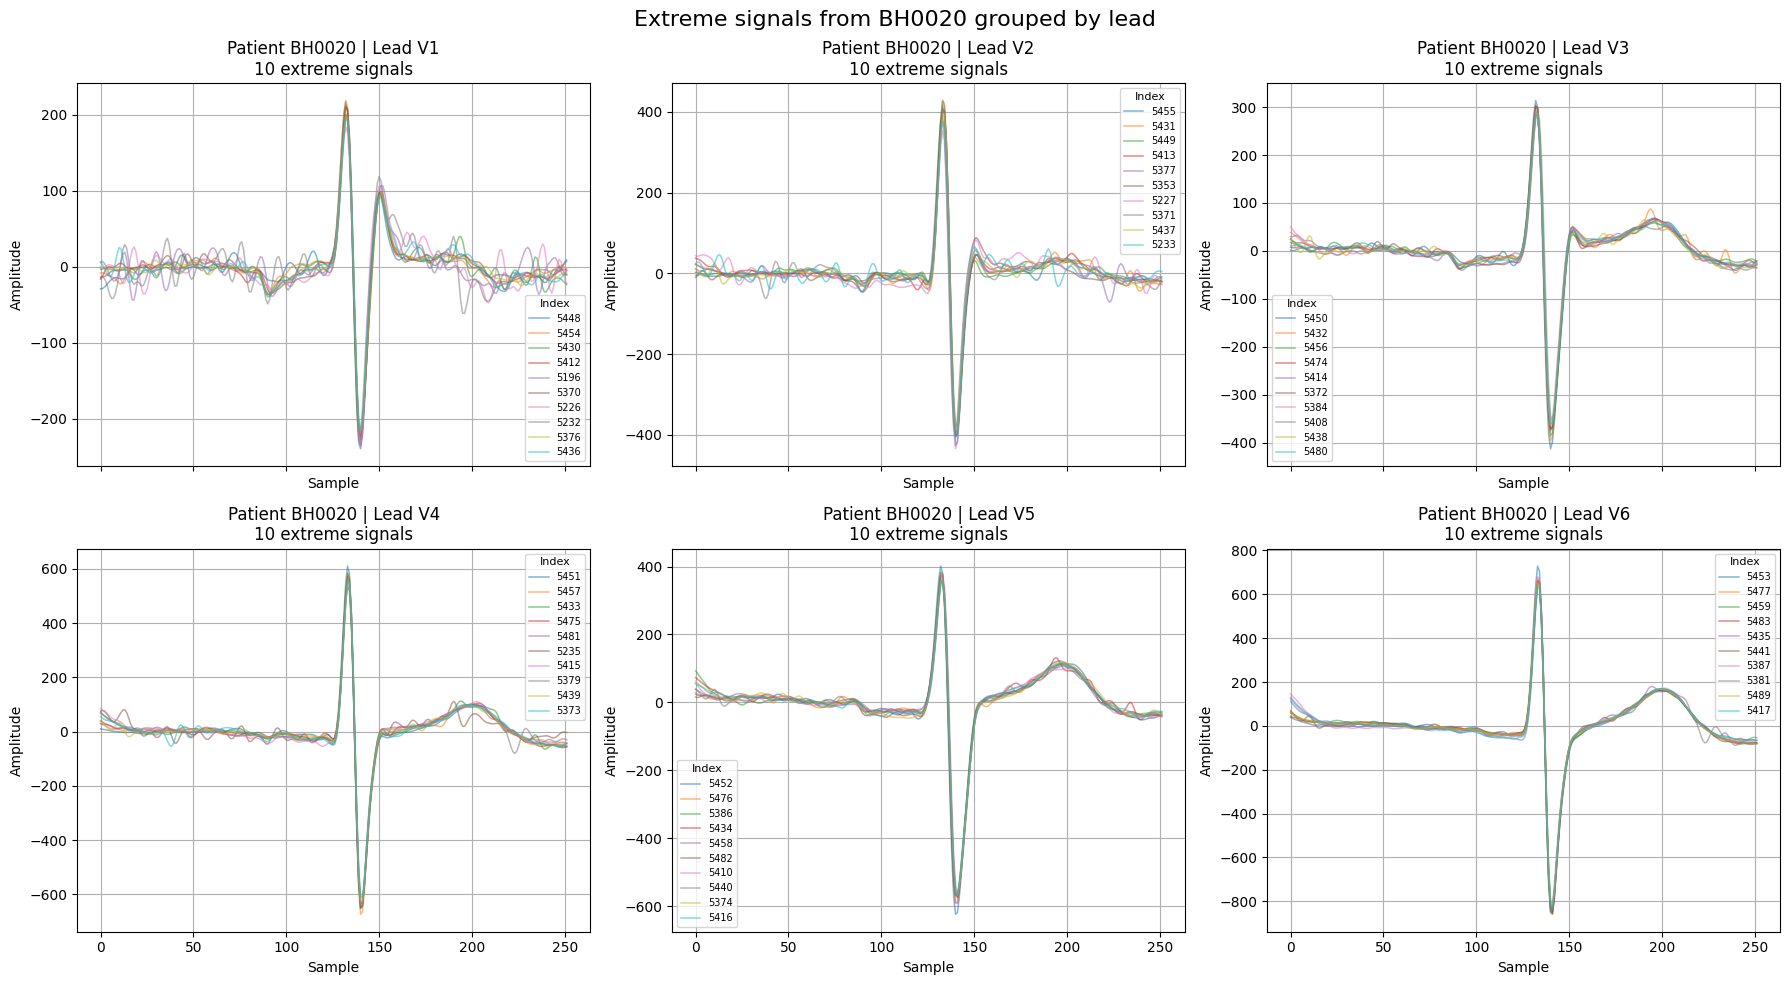

In [31]:
# Leads to plot.
leads_to_plot = [
    "V1",
    "V2",
    "V3",
    "V4",
    "V5",
    "V6",
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18, 10),
    sharex=True,
    sharey=False,
)

for axis, lead in zip(
    axes.ravel(),
    leads_to_plot,
):
    lead_signals = (
        bh0020_extreme_by_lead[
            bh0020_extreme_by_lead["lead"]
            == lead
        ]
    )

    for _, signal_info in lead_signals.iterrows():
        signal_index = int(
            signal_info["signal_index"]
        )

        axis.plot(
            processed_signals_array[
                signal_index
            ],
            alpha=0.55,
            linewidth=1.1,
            label=str(signal_index),
        )

    axis.set_title(
        f"Patient BH0020 | Lead {lead}\n"
        f"{len(lead_signals)} extreme signals"
    )

    axis.set_xlabel("Sample")
    axis.set_ylabel("Amplitude")
    axis.grid(True)

    if len(lead_signals) > 0:
        axis.legend(
            title="Index",
            fontsize=7,
            title_fontsize=8,
        )
    else:
        axis.text(
            0.5,
            0.5,
            "No signals",
            ha="center",
            va="center",
            transform=axis.transAxes,
        )

fig.suptitle(
    "Extreme signals from BH0020 grouped by lead",
    fontsize=16,
)

fig.tight_layout()
plt.show()

A systematic pattern is observed in BH0020/V6:

- All signals have elevated amplitudes.
- The ranges decrease progressively, approximately from 1,580 to 1,190.
- The signal shapes are very similar.
- The pattern does not look like random noise or one corrupted file.

This suggests that BH0020 has a characteristic amplitude scale associated with the recording or patient.

No signal from BH0020 is removed.

#### 3.4.2.3 Analysis of Other Extreme Signals

The unique extreme signals belonging to patients other than BH0020 are plotted for comparison.

In [32]:
# Previously identified unique extreme indices.
all_extreme_indices = sorted(
    set().union(
        set(top_std_indices),
        set(most_negative_min_indices),
        set(most_positive_max_indices),
        set(top_range_indices),
    )
)

# Exclude signals from patient BH0020.
other_extreme_indices = (
    signals_stats[
        signals_stats["signal_index"].isin(
            all_extreme_indices
        )
        & (
            signals_stats["patient_id"]
            != "BH0020"
        )
    ]["signal_index"]
    .to_list()
)

print(
    "Unique extreme signals outside BH0020:",
    len(other_extreme_indices),
)

print(
    other_extreme_indices
)

Unique extreme signals outside BH0020: 10
[9544, 9550, 9562, 9568, 9580, 9592, 9613, 10091, 10488, 10491]


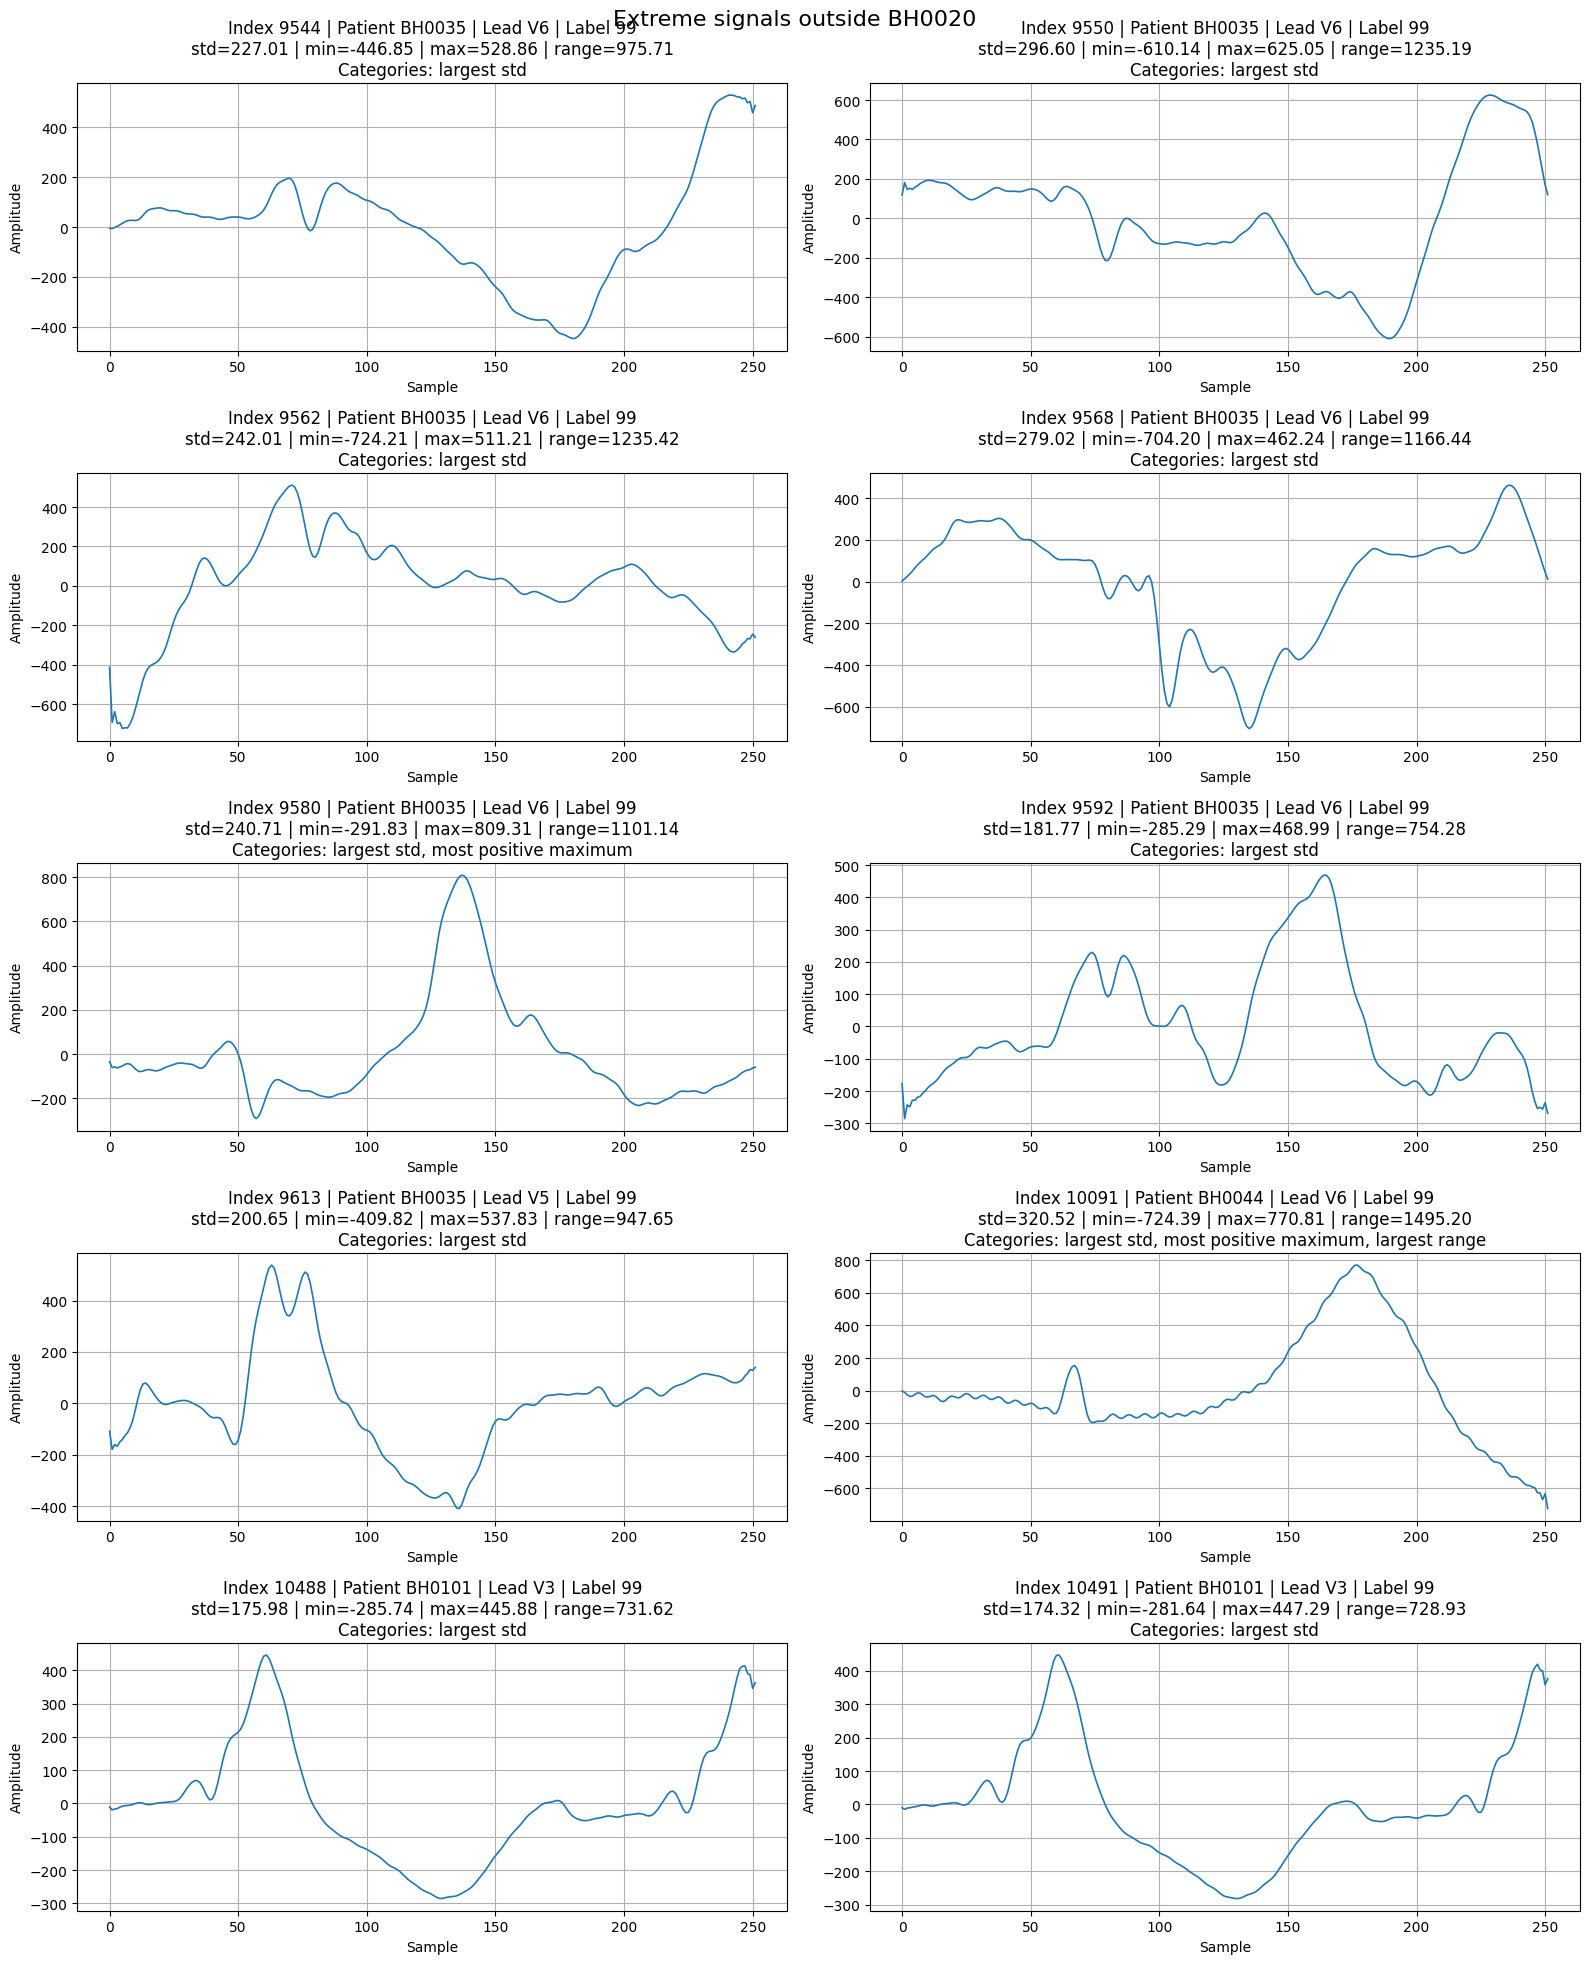

In [33]:
# Plot the remaining extreme signals.

number_of_signals = len(
    other_extreme_indices
)

number_of_columns = 2
number_of_rows = int(
    np.ceil(
        number_of_signals
        / number_of_columns
    )
)

fig, axes = plt.subplots(
    nrows=number_of_rows,
    ncols=number_of_columns,
    figsize=(
        16,
        4 * number_of_rows,
    ),
    squeeze=False,
)

for axis, signal_index in zip(
    axes.ravel(),
    other_extreme_indices,
):
    signal = processed_signals_array[
        signal_index
    ]

    metadata = signals_stats[
        signals_stats["signal_index"]
        == signal_index
    ].iloc[0]

    categories = []

    if signal_index in top_std_indices:
        categories.append(
            "largest std"
        )

    if signal_index in most_negative_min_indices:
        categories.append(
            "most negative minimum"
        )

    if signal_index in most_positive_max_indices:
        categories.append(
            "most positive maximum"
        )

    if signal_index in top_range_indices:
        categories.append(
            "largest range"
        )

    axis.plot(
        signal,
        linewidth=1.2,
    )

    axis.set_title(
        f"Index {signal_index} | "
        f"Patient {metadata['patient_id']} | "
        f"Lead {metadata['lead']} | "
        f"Label {metadata['label']}\n"
        f"std={metadata['std']:.2f} | "
        f"min={metadata['min']:.2f} | "
        f"max={metadata['max']:.2f} | "
        f"range={metadata['range']:.2f}\n"
        f"Categories: {', '.join(categories)}"
    )

    axis.set_xlabel("Sample")
    axis.set_ylabel("Amplitude")
    axis.grid(True)

# Hide unused axes.
for axis in axes.ravel()[
    number_of_signals:
]:
    axis.axis("off")

fig.suptitle(
    "Extreme signals outside BH0020",
    fontsize=16,
)

fig.tight_layout()
plt.show()

##### 3.4.2.3.1 Analysis of Patient BH0035

In [34]:
# Number of extreme signals to plot
# for each lead.
top_n_per_lead = 10

# Select signals from patient BH0035
# with the largest range within each lead.
bh0035_extreme_by_lead = (
    signals_stats[
        signals_stats["patient_id"] == "BH0035"
    ]
    .sort_values(
        ["lead", "range"],
        ascending=[True, False],
    )
    .groupby("lead")
    .head(top_n_per_lead)
)



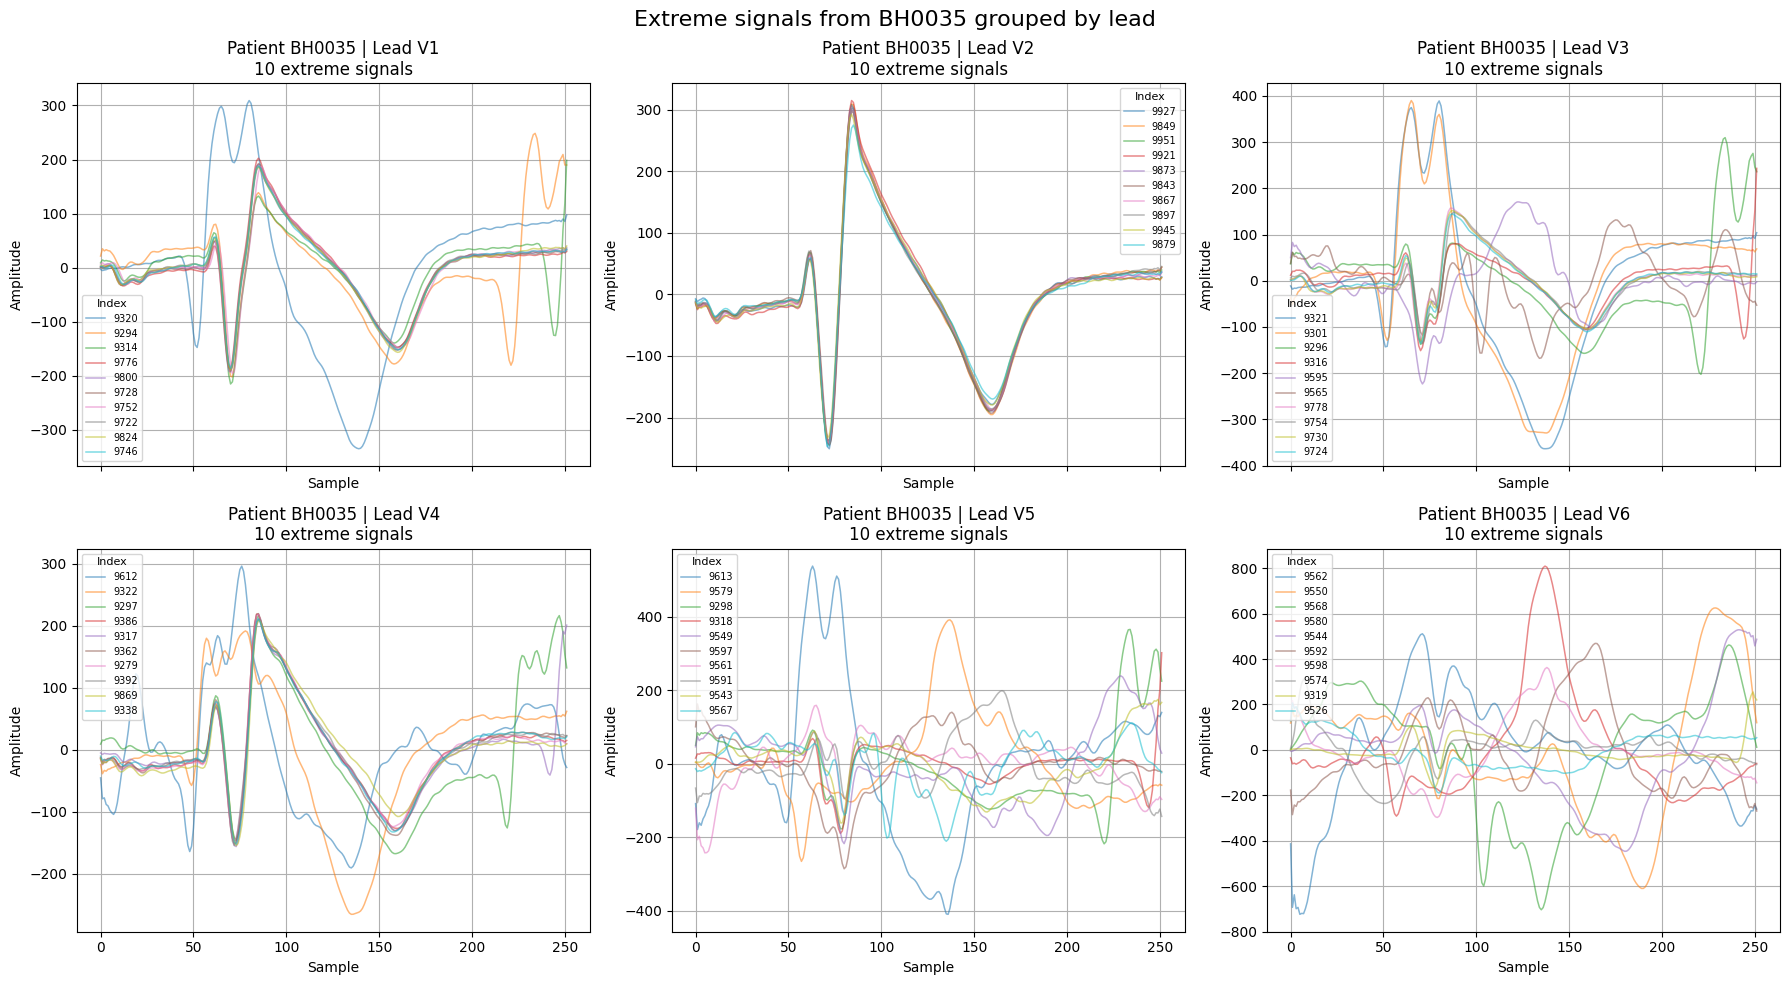

In [35]:
# Leads to plot.
leads_to_plot = [
    "V1",
    "V2",
    "V3",
    "V4",
    "V5",
    "V6",
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18, 10),
    sharex=True,
    sharey=False,
)

for axis, lead in zip(
    axes.ravel(),
    leads_to_plot,
):
    lead_signals = (
        bh0035_extreme_by_lead[
            bh0035_extreme_by_lead["lead"]
            == lead
        ]
    )

    for _, signal_info in lead_signals.iterrows():
        signal_index = int(
            signal_info["signal_index"]
        )

        axis.plot(
            processed_signals_array[
                signal_index
            ],
            alpha=0.55,
            linewidth=1.1,
            label=str(signal_index),
        )

    axis.set_title(
        f"Patient BH0035 | Lead {lead}\n"
        f"{len(lead_signals)} extreme signals"
    )

    axis.set_xlabel("Sample")
    axis.set_ylabel("Amplitude")
    axis.grid(True)

    if len(lead_signals) > 0:
        axis.legend(
            title="Index",
            fontsize=7,
            title_fontsize=8,
        )
    else:
        axis.text(
            0.5,
            0.5,
            "No signals",
            ha="center",
            va="center",
            transform=axis.transAxes,
        )

fig.suptitle(
    "Extreme signals from BH0035 grouped by lead",
    fontsize=16,
)

fig.tight_layout()
plt.show()

##### 3.4.2.3.2 Analysis of Patient BH0044

In [36]:
# Number of extreme signals to plot
# for each lead.
top_n_per_lead = 10

# Select signals from patient BH0044
# with the largest range within each lead.
bh0044_extreme_by_lead = (
    signals_stats[
        signals_stats["patient_id"] == "BH0044"
    ]
    .sort_values(
        ["lead", "range"],
        ascending=[True, False],
    )
    .groupby("lead")
    .head(top_n_per_lead)
)

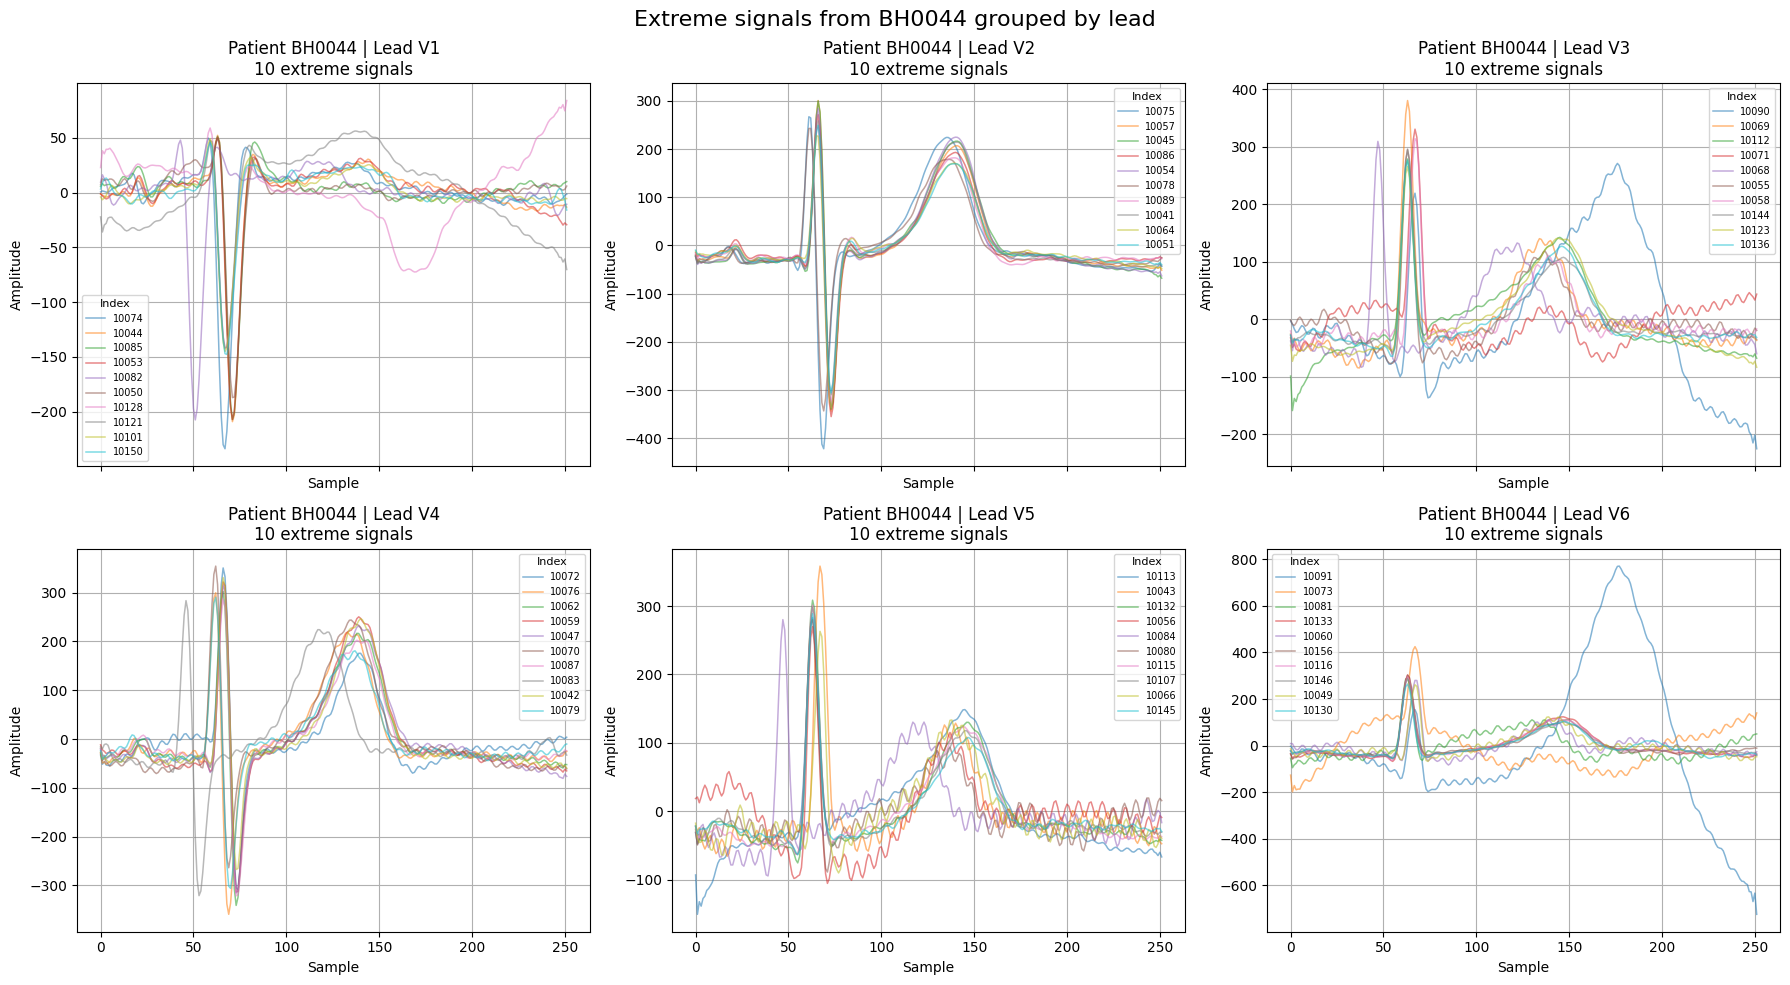

In [37]:
# Leads to plot.
leads_to_plot = [
    "V1",
    "V2",
    "V3",
    "V4",
    "V5",
    "V6",
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18, 10),
    sharex=True,
    sharey=False,
)

for axis, lead in zip(
    axes.ravel(),
    leads_to_plot,
):
    lead_signals = (
        bh0044_extreme_by_lead[
            bh0044_extreme_by_lead["lead"]
            == lead
        ]
    )

    for _, signal_info in lead_signals.iterrows():
        signal_index = int(
            signal_info["signal_index"]
        )

        axis.plot(
            processed_signals_array[
                signal_index
            ],
            alpha=0.55,
            linewidth=1.1,
            label=str(signal_index),
        )

    axis.set_title(
        f"Patient BH0044 | Lead {lead}\n"
        f"{len(lead_signals)} extreme signals"
    )

    axis.set_xlabel("Sample")
    axis.set_ylabel("Amplitude")
    axis.grid(True)

    if len(lead_signals) > 0:
        axis.legend(
            title="Index",
            fontsize=7,
            title_fontsize=8,
        )
    else:
        axis.text(
            0.5,
            0.5,
            "No signals",
            ha="center",
            va="center",
            transform=axis.transAxes,
        )

fig.suptitle(
    "Extreme signals from BH0044 grouped by lead",
    fontsize=16,
)

fig.tight_layout()
plt.show()

When extreme signals are compared with normal signals from the same patient and lead:

- BH0035/V6: the extreme signals have a morphology that differs substantially from the normal signals.
- BH0044/V6: signal 10091 is clearly different from the others.
- BH0101/V3: the extreme signals also depart clearly from the usual pattern.

They do not appear to be merely different beats with the same morphology.

They may correspond to incorrectly segmented signals, artifacts, or different time windows.

#### 3.4.2.4 Checking Positive Outliers

The signals currently considered suspicious are: 9320, 9294, 9595, 9296, 9565, 9612, 9322, 9297, 9613, 9579, 9298, 9568, 9580, 10090, and 10091.
Because removing positive signals may affect the class balance, these candidates are reviewed carefully before exclusion.

In [38]:
posible_outliners = 9320, 9294, 9595, 9296, 9565, 9612, 9322, 9297, 9613, 9579, 9298, 9568, 9580, 10090, 10091


display(
    dataset_index.loc[
        posible_outliners,
        [
            "patient_id",
            "lead",
            "label",
        ],
    ]
)

,patient_id,lead,label
9320,BH0035,V1,99
9294,BH0035,V1,1
9595,BH0035,V3,99
9296,BH0035,V3,99
9565,BH0035,V3,99
9612,BH0035,V4,99
9322,BH0035,V4,99
9297,BH0035,V4,1
9613,BH0035,V5,99
9579,BH0035,V5,1


Positive outliers: 9294, 9297, 9298, 9579

The positive outliers are checked one by one against other positive signals from the same patient and lead.

In [39]:
signal_index_to_include = 9579

# Check that the signal belongs to the requested group.
signal_info = signals_stats[
    signals_stats["signal_index"]
    == signal_index_to_include
].iloc[0]

print(signal_info)


signal_index          9579
mean              0.059465
std             125.240694
min             -265.75179
max             391.630118
range           657.381908
patient_id          BH0035
lead                    V5
label                    1
Name: 9579, dtype: object


Selected indices: [9579, 9292, 9375, 9660, 9351, 9417, 9405, 9756, 9549, 9948]


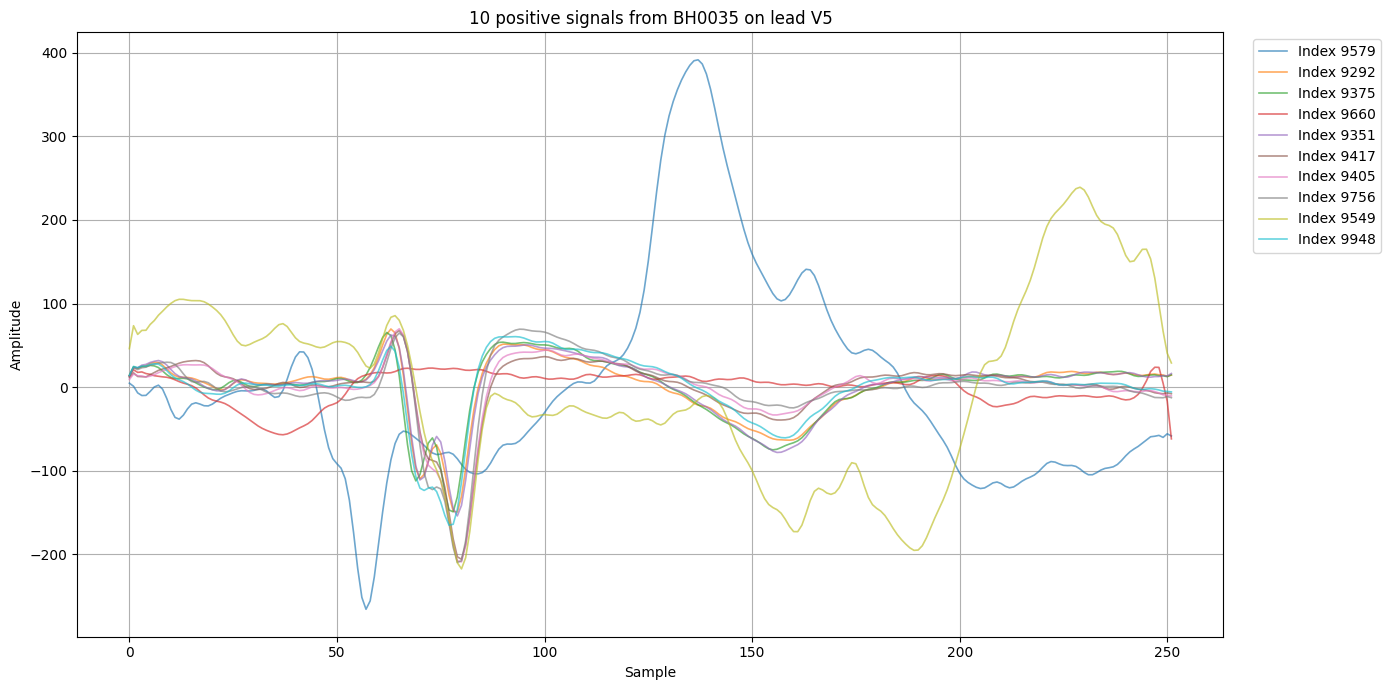

In [40]:
# Select positive signals from BH0035
# corresponding to lead V5.
positive_bh0035_v5 = signals_stats[
    (signals_stats["patient_id"] == "BH0035")
    & (signals_stats["lead"] == "V5")
    & (signals_stats["label"] == 1)
]

# Select nine additional signals.
other_indices = (
    positive_bh0035_v5[
        positive_bh0035_v5["signal_index"]
        != signal_index_to_include
    ]
    .sample(
        n=9,
        random_state=43,
    )["signal_index"]
    .to_list()
)

selected_indices = [
    signal_index_to_include
] + other_indices

print(
    "Selected indices:",
    selected_indices,
)

plt.figure(
    figsize=(14, 7)
)

for signal_index in selected_indices:
    signal = processed_signals_array[
        signal_index
    ]

    plt.plot(
        signal,
        linewidth=1.2,
        alpha=0.65,
        label=f"Index {signal_index}",
    )

plt.title(
    "10 positive signals from BH0035 "
    "on lead V5"
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid(True)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()

#### 3.4.2.5 Outlier Exclusion

The following reviewed outliers are excluded from the cleaned dataset: 9320, 9294, 9595, 9296, 9565, 9612, 9322, 9297, 9613, 9579, 9298, 9568, 9580, 10090, and 10091.

In [41]:
signals_to_exclude = [9320, 9294, 9595, 9296, 9565, 9612, 9322, 9297, 9613, 9579, 9298, 9568, 9580, 10090, 10091]

print(
    "Signals to be provisionally excluded:",
    len(signals_to_exclude),
)

print(
    signals_to_exclude
)

excluded_signals_info = signals_stats[
    signals_stats["signal_index"].isin(
        signals_to_exclude
    )
].copy()

display(
    excluded_signals_info[
        [
            "signal_index",
            "patient_id",
            "lead",
            "label",
            "std",
            "min",
            "max",
            "range",
        ]
    ]
)


Signals to be provisionally excluded: 15
[9320, 9294, 9595, 9296, 9565, 9612, 9322, 9297, 9613, 9579, 9298, 9568, 9580, 10090, 10091]


,signal_index,patient_id,lead,label,std,min,max,range
9294,9294,BH0035,V1,1,94.319447,-201.812562,248.392748,450.205310
9296,9296,BH0035,V3,99,99.990320,-202.605838,309.657684,512.263522
9297,9297,BH0035,V4,1,97.350823,-167.807608,216.347531,384.155139
9298,9298,BH0035,V5,1,112.069401,-218.013570,365.548970,583.562539
9320,9320,BH0035,V1,99,146.875783,-334.743441,309.057033,643.800474
9322,9322,BH0035,V4,99,107.690828,-265.666969,191.615868,457.282837
9565,9565,BH0035,V3,99,66.243365,-167.987255,131.600385,299.587640
9568,9568,BH0035,V6,99,279.024874,-704.195435,462.244623,1166.440058
9579,9579,BH0035,V5,1,125.240694,-265.751790,391.630118,657.381908
9580,9580,BH0035,V6,99,240.706890,-291.833458,809.307150,1101.140608


In [42]:
keep_mask = ~np.isin(
    np.arange(
        len(processed_signals_array)
    ),
    signals_to_exclude,
)

filtered_signals = (
    processed_signals_array[keep_mask]
)

filtered_dataset_index = (
    dataset_index.loc[keep_mask]
    .reset_index(drop=True)
)

signals_clean = filtered_signals

dataset_index_clean = (
    filtered_dataset_index
)


print(
    "Signals before:",
    len(processed_signals_array),
)

print(
    "Signals after:",
    len(filtered_signals),
)

print(
    "Excluded signals:",
    len(signals_to_exclude),
)

Signals before: 10592
Signals after: 10577
Excluded signals: 15


In [43]:
# Signal statistics after removing the excluded signals

signals_stats_clean = pd.DataFrame({
    "mean": np.mean(signals_clean, axis=1),
    "std": np.std(signals_clean, axis=1),
    "min": np.min(signals_clean, axis=1),
    "max": np.max(signals_clean, axis=1),
    "range": np.ptp(signals_clean, axis=1),
})

signals_stats_clean.describe()



,mean,std,min,max,range
count,1.057700e+04,10577.000000,10577.000000,10577.000000,10577.000000
mean,-5.332438e-03,61.245858,-271.651036,149.133354,420.784390
std,3.675954e-02,27.089991,126.950002,102.118347,183.582947
min,-5.596548e-01,8.753073,-859.177306,19.322702,38.765749
25%,-7.534009e-14,40.151400,-345.656610,81.782905,287.551267
50%,-3.383537e-16,55.946133,-240.354081,117.840206,373.473238
75%,6.767074e-15,77.001455,-184.060881,181.723320,524.509903
max,4.045342e-01,296.603840,-16.989158,728.692981,1580.234800


In [44]:
# Add these statistics to the dataset.

signals_stats_clean = signals_stats_clean.copy()

signals_stats_clean["signal_index"] = (
    signals_stats_clean.index
)
signals_stats_clean["patient_id"] = dataset_index_clean["patient_id"].to_numpy()
signals_stats_clean["lead"] = dataset_index_clean["lead"].to_numpy()
signals_stats_clean["label"] = dataset_index_clean["label"].to_numpy()

signals_stats_clean.head()

,mean,std,min,max,range,signal_index,patient_id,lead,label
0,-5.620460e-03,41.655354,-236.368822,62.242692,298.611514,0,BH0002,V1,99
1,-2.842341e-02,35.001990,-195.734400,57.378970,253.113370,1,BH0002,V2,99
2,-6.478057e-03,43.234419,-238.664485,81.173277,319.837762,2,BH0002,V3,99
3,-2.401302e-02,37.492556,-178.630701,94.362152,272.992853,3,BH0002,V4,99
4,-2.729386e-14,42.252041,-220.947176,101.378403,322.325579,4,BH0002,V5,1


### 3.4.3 Per-Signal Z-Score Normalization

Each signal is normalized independently. For every row, its mean is subtracted and the result is divided by its standard deviation.

After normalization, each signal should have a mean close to 0 and a standard deviation close to 1.

The normalized signals are saved in a separate `.npz` file so that the original `processed_signals_252.npz` file is preserved.

In [45]:
# Calculate the mean of each signal independently.
signal_means = np.mean(
    signals_clean,
    axis=1,
    keepdims=True,
)

# Calculate the standard deviation of each signal.
signal_stds = np.std(
    signals_clean,
    axis=1,
    keepdims=True,
)

# Check that no signal has a zero standard deviation.
# A constant signal could not be normalized correctly.
if np.any(signal_stds == 0):
    raise ValueError(
        "At least one signal has zero standard deviation."
    )

# Apply z-score normalization to each signal.
normalized_signals = (
    signals_clean - signal_means
) / signal_stds

print(
    f"Normalized signals shape: "
    f"{normalized_signals.shape}"
)

print(
    f"Data type: "
    f"{normalized_signals.dtype}"
)

Normalized signals shape: (10577, 252)
Data type: float64


#### Validating the Normalization

The means and standard deviations of the normalized signals are checked to confirm that they are approximately 0 and 1, respectively.

In [46]:
# Calculate the mean of each normalized signal.
normalized_means = np.mean(
    normalized_signals,
    axis=1,
)

# Calculate the standard deviation of each normalized signal.
normalized_stds = np.std(
    normalized_signals,
    axis=1,
)

print(
    f"Minimum mean: "
    f"{normalized_means.min():.8f}"
)

print(
    f"Maximum mean: "
    f"{normalized_means.max():.8f}"
)

print(
    f"Minimum standard deviation: "
    f"{normalized_stds.min():.8f}"
)

print(
    f"Maximum standard deviation: "
    f"{normalized_stds.max():.8f}"
)

# Check that each signal has a mean close to 0
# and a standard deviation close to 1.

means_are_zero = np.allclose(
    normalized_means,
    0,
    atol=1e-5,
)

stds_are_one = np.allclose(
    normalized_stds,
    1,
    atol=1e-5,
)

print(
    "All means are approximately 0:",
    means_are_zero,
)

print(
    "All standard deviations are approximately 1:",
    stds_are_one,
)

assert means_are_zero
assert stds_are_one

print(
    "✓ Z-score normalization was applied correctly."
)

Minimum mean: -0.00000000
Maximum mean: 0.00000000
Minimum standard deviation: 1.00000000
Maximum standard deviation: 1.00000000
All means are approximately 0: True
All standard deviations are approximately 1: True
✓ Z-score normalization was applied correctly.


#### Saving the Normalized Signals

The normalized signals are saved to `normalized_signals_clean.npz`, together with the metadata required to identify each signal.

In [47]:
# Save the normalized signals in a separate file.
np.savez_compressed(
    "data/normalized_signals_clean.npz",
    signals=normalized_signals,
    patient_id=dataset_index_clean[
        "patient_id"
    ].to_numpy(dtype=str),
    lead=dataset_index_clean[
        "lead"
    ].to_numpy(dtype=str),
    label=dataset_index_clean[
        "label"
    ].to_numpy(dtype=int),
    mat_path=dataset_index_clean[
        "mat_path"
    ].astype(str).to_numpy(dtype=str),
)

print(
    "Saved file: "
    "data/normalized_signals_clean.npz"
)


Saved file: data/normalized_signals_clean.npz


In [48]:
# Save non-normalized signals.
# Save the non-normalized signals in a separate file.

# normalized_signals_clean -> nonormalized_signals_clean
# normalized_signals -> signals_clean

np.savez_compressed(
    "data/nonormalized_signals_clean.npz",
    signals=signals_clean,
    patient_id=dataset_index_clean[
        "patient_id"
    ].to_numpy(dtype=str),
    lead=dataset_index_clean[
        "lead"
    ].to_numpy(dtype=str),
    label=dataset_index_clean[
        "label"
    ].to_numpy(dtype=int),
    mat_path=dataset_index_clean[
        "mat_path"
    ].astype(str).to_numpy(dtype=str),
)

print(
    "Saved file: "
    "data/nonormalized_signals_clean.npz"
)

Saved file: data/nonormalized_signals_clean.npz


### Verifying the Saved Normalized Data

In [ ]:
# Load the normalized file to verify that it was saved correctly.
normalized_data = np.load(
    "data/normalized_signals_clean.npz"
)

normalized_signals_clean = normalized_data["signals"]
patient_ids = normalized_data["patient_id"]
leads = normalized_data["lead"]
labels = normalized_data["label"]
mat_paths = normalized_data["mat_path"]


print("✓ Signals and metadata have the same length.")


print(
    f"Number of patients: "
    f"{len(np.unique(patient_ids))}"
)

print(
    f"Number of leads: "
    f"{len(np.unique(leads))}"
)

print(
    f"Number of labels: "
    f"{len(np.unique(labels))}"
)

print(
    f"Number of paths: "
    f"{len(np.unique(mat_paths))}"
)

✓ Signals and metadata have the same length.
Shape: (10577, 252)
Signal data type: float64
Number of patients: 33
Number of leads: 6
Number of labels: 2
Number of paths: 10577


In [ ]:
# Load the non-normalized file to verify that it was saved correctly.
nonormalized_data = np.load(
    "data/nonormalized_signals_clean.npz"
)

nonormalized_signals_clean = nonormalized_data["signals"]
patient_ids = nonormalized_data["patient_id"]
leads = nonormalized_data["lead"]
labels = nonormalized_data["label"]
mat_paths = nonormalized_data["mat_path"]

assert nonormalized_signals_clean.shape[0] == len(patient_ids)
assert nonormalized_signals_clean.shape[0] == len(leads)
assert nonormalized_signals_clean.shape[0] == len(labels)
assert nonormalized_signals_clean.shape[0] == len(mat_paths)
print("✓ Signals and metadata have the same length.")


print(
    f"Shape: "
    f"{nonormalized_signals_clean.shape}"
)

print(
    f"Signal data type: "
    f"{nonormalized_signals_clean.dtype}"
)

print(
    f"Number of patients: "
    f"{len(np.unique(patient_ids))}"
)

print(
    f"Number of leads: "
    f"{len(np.unique(leads))}"
)

print(
    f"Number of labels: "
    f"{len(np.unique(labels))}"
)

print(
    f"Number of paths: "
    f"{len(np.unique(mat_paths))}"
)

✓ Signals and metadata have the same length.
Shape: (10577, 252)
Signal data type: float64
Number of patients: 33
Number of leads: 6
Number of labels: 2
Number of paths: 10577


In [51]:
normalized_data = np.load(
    "data/normalized_signals_clean.npz"
)

normalized_signals_clean = (
    normalized_data["signals"]
)

patient_ids = normalized_data[
    "patient_id"
]

leads = normalized_data[
    "lead"
]

labels = normalized_data[
    "label"
]

mat_paths = normalized_data[
    "mat_path"
]

print("Variables almacenadas:")
print(normalized_data.files)

Variables almacenadas:
['signals', 'patient_id', 'lead', 'label', 'mat_path']


In [56]:
nonormalized_data = np.load(
    "data/nonormalized_signals_clean.npz"
)

nonormalized_signals_clean = (
    nonormalized_data["signals"]
)

patient_ids = nonormalized_data[
    "patient_id"
]

leads = nonormalized_data[
    "lead"
]

labels = nonormalized_data[
    "label"
]

mat_paths = nonormalized_data[
    "mat_path"
]

print("Variables almacenadas:")
print(nonormalized_data.files)

Variables almacenadas:
['signals', 'patient_id', 'lead', 'label', 'mat_path']


In [70]:
# Signal statistics after normalization

signals_stats_norm = pd.DataFrame({
    "mean": np.mean(normalized_signals_clean, axis=1),
    "std": np.std(normalized_signals_clean, axis=1),
    "min": np.min(normalized_signals_clean, axis=1),
    "max": np.max(normalized_signals_clean, axis=1),
    "range": np.ptp(normalized_signals_clean, axis=1),
})

signals_stats_norm.describe()

,mean,std,min,max,range
count,1.057700e+04,1.057700e+04,10577.000000,10577.000000,10577.000000
mean,7.736124e-19,1.000000e+00,-4.605637,2.388520,6.994157
std,2.464715e-17,8.311262e-17,1.295468,0.967517,1.162359
min,-1.127846e-16,1.000000e+00,-7.817221,0.499022,3.252206
25%,-1.409807e-17,1.000000e+00,-5.581907,1.664170,6.219135
50%,0.000000e+00,1.000000e+00,-5.040419,2.247622,7.129604
75%,1.409807e-17,1.000000e+00,-3.925006,2.908444,7.763432
max,1.268826e-16,1.000000e+00,-0.843982,6.290482,10.750940


In [71]:
# Signal statistics no normalized

signals_stats_nonorm = pd.DataFrame({
    "mean": np.mean(nonormalized_signals_clean, axis=1),
    "std": np.std(nonormalized_signals_clean, axis=1),
    "min": np.min(nonormalized_signals_clean, axis=1),
    "max": np.max(nonormalized_signals_clean, axis=1),
    "range": np.ptp(nonormalized_signals_clean, axis=1),
})

signals_stats_nonorm.describe()

,mean,std,min,max,range
count,1.057700e+04,10577.000000,10577.000000,10577.000000,10577.000000
mean,-5.332438e-03,61.245858,-271.651036,149.133354,420.784390
std,3.675954e-02,27.089991,126.950002,102.118347,183.582947
min,-5.596548e-01,8.753073,-859.177306,19.322702,38.765749
25%,-7.534009e-14,40.151400,-345.656610,81.782905,287.551267
50%,-3.383537e-16,55.946133,-240.354081,117.840206,373.473238
75%,6.767074e-15,77.001455,-184.060881,181.723320,524.509903
max,4.045342e-01,296.603840,-16.989158,728.692981,1580.234800


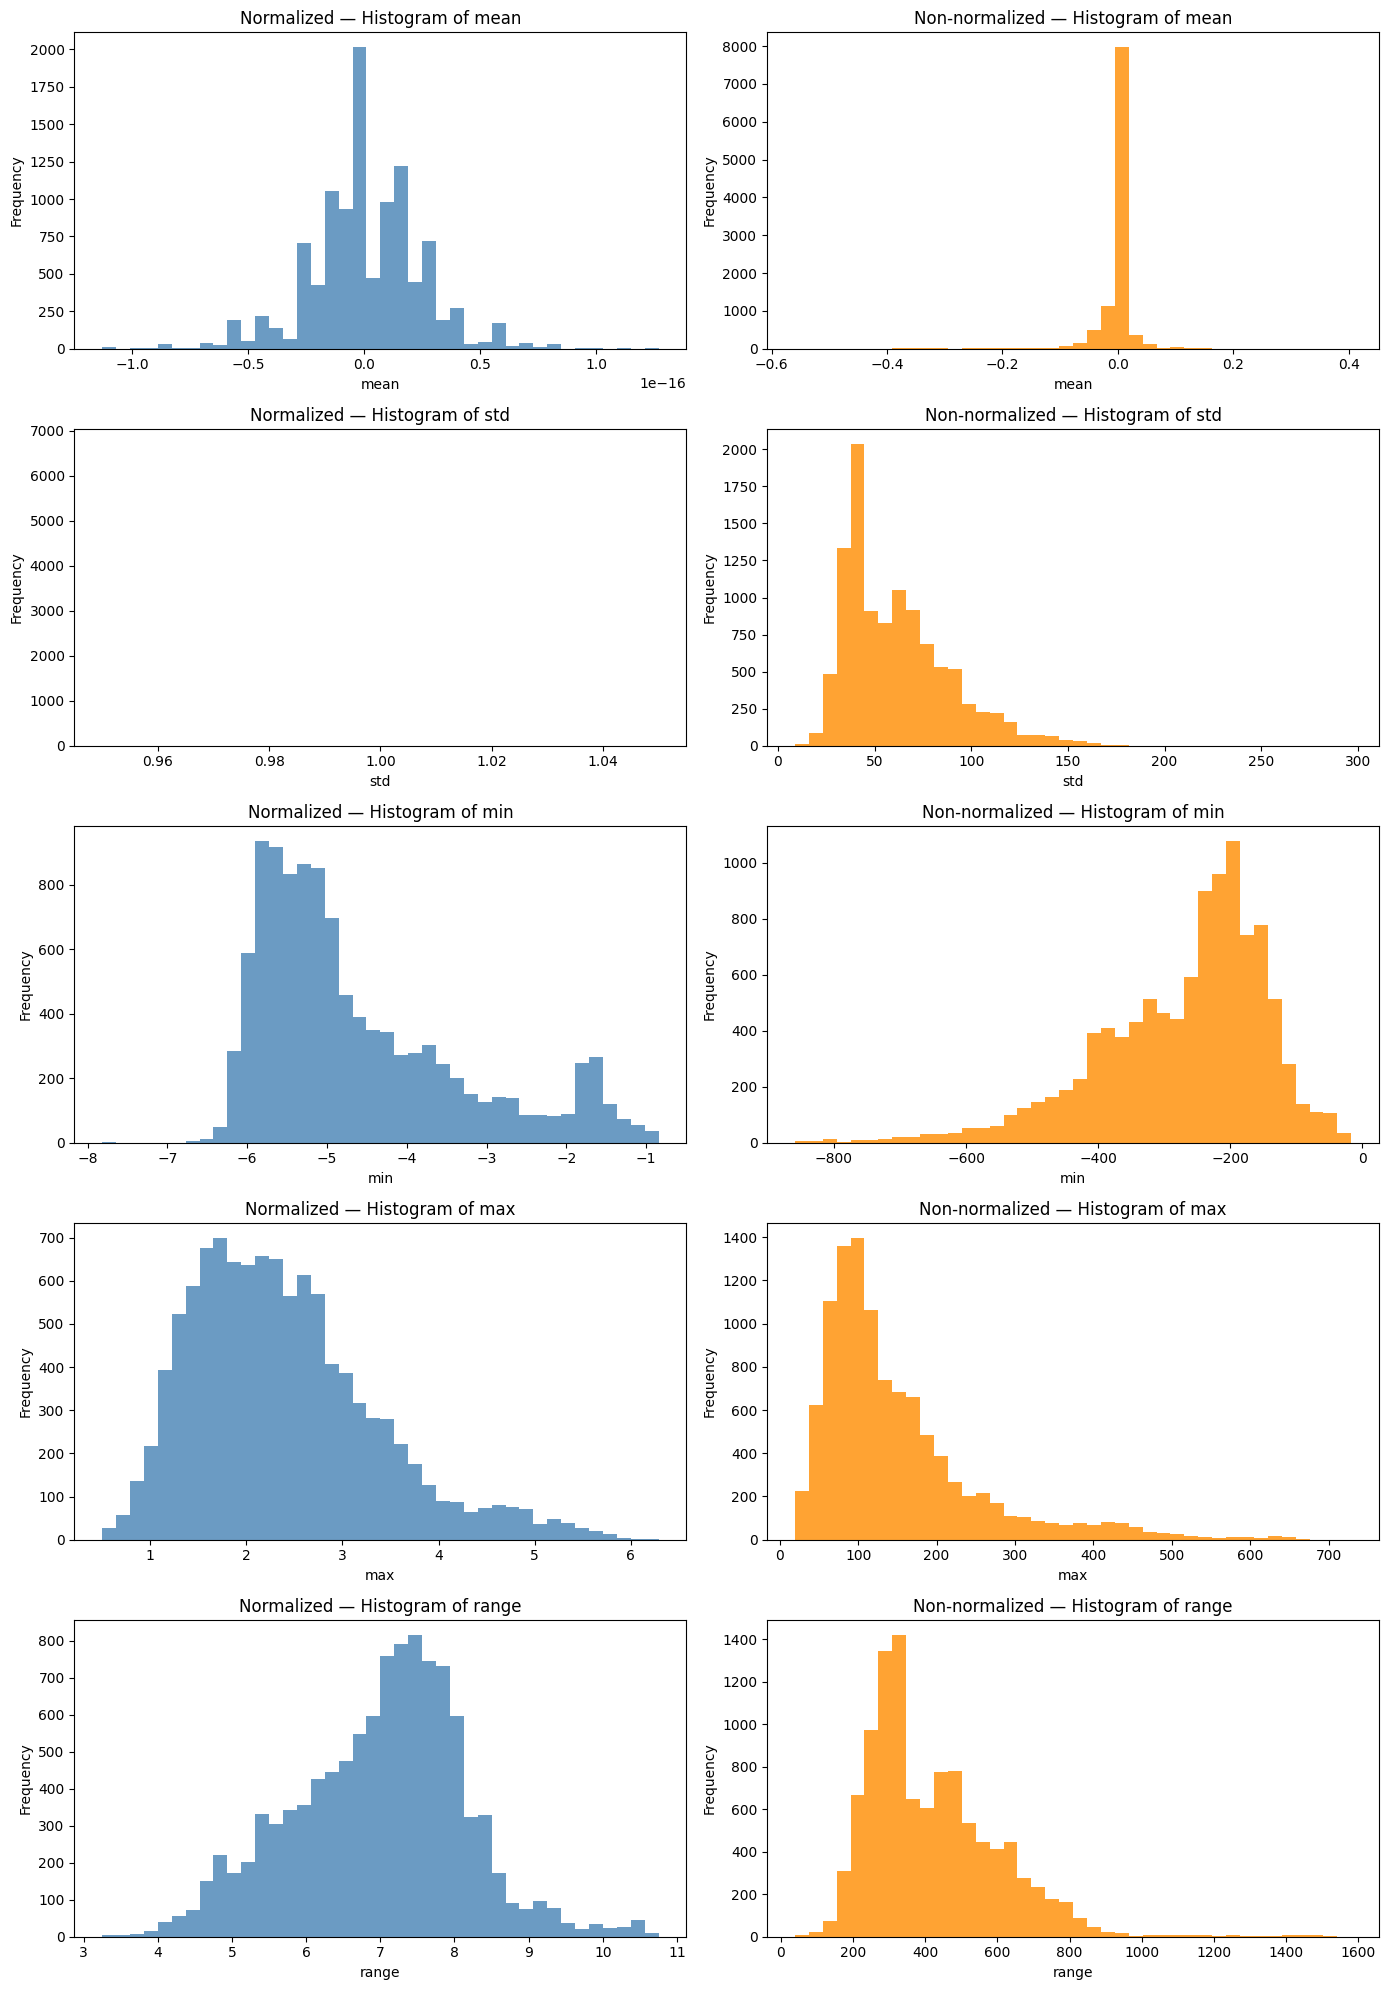

In [73]:
stats_columns = [
    "mean",
    "std",
    "min",
    "max",
    "range",
]

fig, axes = plt.subplots(
    nrows=len(stats_columns),
    ncols=2,
    figsize=(14, 4 * len(stats_columns)),
)

for row_number, column in enumerate(stats_columns):
    normalized_values = signals_stats_norm[column].dropna()
    nonormalized_values = signals_stats_nonorm[column].dropna()

    axes[row_number, 0].hist(
        normalized_values,
        bins=40,
        color="steelblue",
        alpha=0.8,
    )
    axes[row_number, 0].set_title(
        f"Normalized — Histogram of {column}"
    )
    axes[row_number, 0].set_xlabel(column)
    axes[row_number, 0].set_ylabel("Frequency")

    axes[row_number, 1].hist(
        nonormalized_values,
        bins=40,
        color="darkorange",
        alpha=0.8,
    )
    axes[row_number, 1].set_title(
        f"Non-normalized — Histogram of {column}"
    )
    axes[row_number, 1].set_xlabel(column)
    axes[row_number, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## 3.5 Final Preprocessing Summary

This notebook completed the main preprocessing and quality-control steps for the ECG signals. The prepared dataset index was loaded and checked for the metadata required to locate each `.mat` file, identify its signal variable, determine its original length, and associate it with a patient, lead, and class label.

The original dataset contained 10,592 signals: 6,977 with 252 samples and 3,615 with 801 samples. Baseline drift was removed from every signal using `scipy.signal.detrend`. Signals with 801 samples were then resampled to 252 samples using `scipy.signal.resample_poly`, while signals that already had 252 samples were not resampled.

Extreme-signal statistics were analyzed at patient and lead level. After reviewing the candidates, 15 signal indices were excluded from the cleaned dataset, leaving 10,577 signals. The resulting processed matrix has shape `(10577, 252)`.

The cleaned, non-normalized signals are stored in `signals_clean`, with their corresponding metadata in `dataset_index_clean`. Per-signal z-score normalization was then applied and validated, and the normalized signals and metadata were saved to `data/normalized_signals_clean.npz`.

### Processing Summary

| Item | Result |
|---|---:|
| Original signals | 10,592 |
| Original signals with 252 samples | 6,977 |
| Original signals with 801 samples | 3,615 |
| Excluded signal indices | 15 |
| Cleaned signals | 10,577 |
| Final signal length | 252 samples |
| Final signal matrix | `(10577, 252)` |
| Expected normalized mean per signal | approximately 0 |
| Expected normalized standard deviation per signal | approximately 1 |

### Output Files

- `data/processed_signals_252.npz`: resampled signals before outlier cleaning.
- `data/nonormalized_signals_clean.npz`: cleaned, non-normalized signals and metadata.
- `data/normalized_signals_clean.npz`: cleaned, z-score-normalized signals and metadata.

The data is now ready for the patient-level train-validation-test split. That split should preserve patient identity so that recordings from the same patient cannot appear in different subsets.